In [ ]:

from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:

import os

folder_path = '/content/drive/MyDrive/Big data project'

files = os.listdir(folder_path)

print("Files in our project folder:")
for file in files:
    print(file)


Files in our project folder:
All_Beauty.jsonl
Amazon all beautyDS.ipynb


In [ ]:

import pandas as pd
from pathlib import Path

# 1. Locate the dataset
folder_path = Path('/content/drive/MyDrive/Big data project')

dataset_files = list(folder_path.glob('All_Beauty.jsonl*'))

if not dataset_files:
    raise FileNotFoundError("Dataset not found!")

file_path = dataset_files[0]

# 2. Read only the first 5 reviews
df_sample = pd.read_json(
    file_path,
    lines=True,
    nrows=5,
    compression='infer'
)

# 3. Display the dataset columns
print("Dataset Columns:")
print(df_sample.columns.tolist())

# 4. Display sample reviews
print("\nFirst 5 Reviews:")
display(df_sample)


Dataset Columns:
['rating', 'title', 'text', 'images', 'asin', 'parent_asin', 'user_id', 'timestamp', 'helpful_vote', 'verified_purchase']

First 5 Reviews:


,rating,title,text,images,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase
0,5,Such a lovely scent but not overpowering.,This spray is really nice. It smells really go...,[],B00YQ6X8EO,B00YQ6X8EO,AGKHLEW2SOWHNMFQIJGBECAF7INQ,2020-05-05 14:08:48.923,0,True
1,4,Works great but smells a little weird.,"This product does what I need it to do, I just...",[],B081TJ8YS3,B081TJ8YS3,AGKHLEW2SOWHNMFQIJGBECAF7INQ,2020-05-04 18:10:55.070,1,True
2,5,Yes!,"Smells good, feels great!",[],B07PNNCSP9,B097R46CSY,AE74DYR3QUGVPZJ3P7RFWBGIX7XQ,2020-05-16 21:41:06.052,2,True
3,1,Synthetic feeling,Felt synthetic,[],B09JS339BZ,B09JS339BZ,AFQLNQNQYFWQZPJQZS6V3NZU4QBQ,2022-01-28 18:13:50.220,0,True
4,5,A+,Love it,[],B08BZ63GMJ,B08BZ63GMJ,AFQLNQNQYFWQZPJQZS6V3NZU4QBQ,2020-12-30 10:02:43.534,0,True


In [ ]:

import pandas as pd

# Dataset location in Google Drive
file_path = '/content/drive/MyDrive/Big data project/All_Beauty.jsonl'

# Load the dataset
df = pd.read_json(file_path, lines=True)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)


Dataset loaded successfully!
Dataset Shape: (701528, 10)


In [ ]:

print("Total Reviews:", len(df))
print("Total Columns:", df.shape[1])

print("\nRating Distribution:")
print(df["rating"].value_counts().sort_index())


Total Reviews: 701528
Total Columns: 10

Rating Distribution:
rating
1    102080
2     43034
3     56307
4     79381
5    420726
Name: count, dtype: int64


In [ ]:

# Step 2: Data Quality Assessment

# Missing values
missing = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (df.isnull().mean() * 100).round(2)
})

print("Missing Values:")
display(missing)

# Duplicate reviews
duplicates = df.duplicated(
    subset=['user_id', 'asin', 'timestamp', 'text']
).sum()

print("\nDuplicate Reviews:", duplicates)


Missing Values:


,Missing_Count,Missing_Percentage
rating,0,0.0
title,0,0.0
text,0,0.0
images,0,0.0
asin,0,0.0
parent_asin,0,0.0
user_id,0,0.0
timestamp,0,0.0
helpful_vote,0,0.0
verified_purchase,0,0.0



Duplicate Reviews: 7276


In [ ]:

# Step 2: Check Duplicates and Empty Text

print("Total Reviews:", len(df))

print("Repeated Texts:",
      df["text"].duplicated().sum())

print("Same User, Product, Time, and Text:",
      df.duplicated(
          subset=["user_id", "asin", "timestamp", "text"]
      ).sum())

print("Empty Review Texts:",
      df["text"].astype("string").str.strip().eq("").sum())

print("Empty Titles:",
      df["title"].astype("string").str.strip().eq("").sum())


Total Reviews: 701528
Repeated Texts: 57899
Same User, Product, Time, and Text: 7276
Empty Review Texts: 720
Empty Titles: 0


In [ ]:

# Step 3: Inspect Potential Duplicate Reviews

key_cols = ["user_id", "asin", "timestamp", "text"]

# Find all rows sharing the same key
dup_rows = df[
    df.duplicated(subset=key_cols, keep=False)
].copy()

print("Rows in duplicate groups:", len(dup_rows))

# Check whether other important fields differ
check_cols = [
    "rating",
    "title",
    "helpful_vote",
    "verified_purchase",
    "parent_asin"
]

differences = (
    dup_rows.groupby(key_cols, dropna=False)[check_cols]
    .nunique(dropna=False)
)

print("\nGroups with differences in other fields:")
print(differences.gt(1).sum())

print("\nTotal groups with any difference:")
print(differences.gt(1).any(axis=1).sum())


Rows in duplicate groups: 13415

Groups with differences in other fields:
rating               0
title                0
helpful_vote         1
verified_purchase    0
parent_asin          0
dtype: int64

Total groups with any difference:
1


In [ ]:

# Step 4: Check Image Differences

image_differences = (
    dup_rows.assign(
        images_repr=dup_rows["images"].map(repr)
    )
    .groupby(key_cols, dropna=False)["images_repr"]
    .nunique(dropna=False)
)

print("Groups with different images:")
print((image_differences > 1).sum())

# Examine the exceptional helpful_vote group
conflict_keys = differences.index[
    differences.gt(1).any(axis=1)
]

if len(conflict_keys) > 0:
    conflict = (
        dup_rows.set_index(key_cols)
        .loc[[conflict_keys[0]]]
    )

    print("\nHelpful votes in the exceptional group:")
    print(conflict["helpful_vote"].value_counts())


Groups with different images:
0

Helpful votes in the exceptional group:
helpful_vote
0    1
1    1
Name: count, dtype: int64


In [ ]:

# Step 5: Data Cleaning

# 1. Define duplicate key
key_cols = [
    "user_id", "asin", "timestamp", "text"
]

# 2. Keep the highest helpful_vote
# when duplicate records exist
df_clean = (
    df.sort_values(
        "helpful_vote",
        ascending=False,
        kind="stable"
    )
    .drop_duplicates(
        subset=key_cols,
        keep="first"
    )
    .sort_index()
    .copy()
)

duplicates_removed = len(df) - len(df_clean)

# 3. Remove reviews with empty text
valid_text = (
    df_clean["text"]
    .fillna("")
    .astype(str)
    .str.strip()
    .ne("")
)

empty_removed = (~valid_text).sum()

df_clean = df_clean.loc[valid_text].copy()

# 4. Cleaning summary
print("Original Reviews:", len(df))
print("Duplicates Removed:", duplicates_removed)
print("Empty Texts Removed:", empty_removed)
print("Cleaned Reviews:", len(df_clean))

print("\nRemaining Duplicates:",
      df_clean.duplicated(
          subset=key_cols
      ).sum())

print("Remaining Empty Texts:",
      df_clean["text"].str.strip().eq("").sum())


Original Reviews: 701528
Duplicates Removed: 7276
Empty Texts Removed: 705
Cleaned Reviews: 693547

Remaining Duplicates: 0
Remaining Empty Texts: 0


In [ ]:

# Step 6: Ratings and Temporal Coverage

import pandas as pd

# 1. Rating distribution
print("Rating Distribution:")
print(df_clean["rating"].value_counts().sort_index())

print("\nRating Percentages:")
print(
    df_clean["rating"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

# 2. Convert timestamps to dates
df_clean["review_date"] = pd.to_datetime(
    df_clean["timestamp"],
    errors="coerce"
)

# 3. Date range
print("\nEarliest Review:")
print(df_clean["review_date"].min())

print("\nLatest Review:")
print(df_clean["review_date"].max())

print("\nInvalid Dates:")
print(df_clean["review_date"].isna().sum())


Rating Distribution:
rating
1    100756
2     42577
3     55696
4     78546
5    415972
Name: count, dtype: int64

Rating Percentages:
rating
1    14.53
2     6.14
3     8.03
4    11.33
5    59.98
Name: proportion, dtype: float64

Earliest Review:
2000-11-01 04:24:18

Latest Review:
2023-09-09 00:39:36.666000

Invalid Dates:
0


Total Months: 275
Months with Reviews: 265
Months without Reviews: 10

Reviews per Year:
review_date
2000         1
2001        11
2002        24
2003        56
2004       130
2005       265
2006       416
2007      1150
2008      1251
2009      1198
2010      1568
2011      1855
2012      2774
2013      7882
2014     16107
2015     35844
2016     62042
2017     67351
2018     71966
2019     98148
2020    125427
2021    123279
2022     60654
2023     14148
dtype: int64


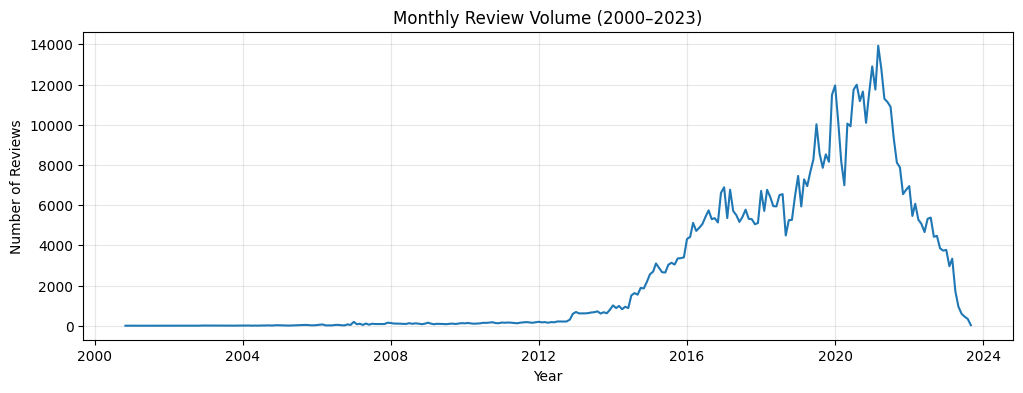

In [ ]:

# Step 7: Monthly Review Distribution

import matplotlib.pyplot as plt

# Count reviews per month
monthly_reviews = (
    df_clean
    .set_index("review_date")
    .resample("MS")
    .size()
)

print("Total Months:", len(monthly_reviews))

print("Months with Reviews:",
      (monthly_reviews > 0).sum())

print("Months without Reviews:",
      (monthly_reviews == 0).sum())

print("\nReviews per Year:")
print(
    monthly_reviews
    .groupby(monthly_reviews.index.year)
    .sum()
)

# Plot monthly review counts
plt.figure(figsize=(12, 4))

plt.plot(
    monthly_reviews.index,
    monthly_reviews.values
)

plt.title("Monthly Review Volume (2000–2023)")
plt.xlabel("Year")
plt.ylabel("Number of Reviews")
plt.grid(alpha=0.3)
plt.show()


In [ ]:

# Step 8: Negative Review Trends by Year

# Define negative reviews: 1 or 2 stars
df_clean["is_negative"] = (
    df_clean["rating"] <= 2
)

# Extract year
df_clean["year"] = (
    df_clean["review_date"].dt.year
)

# Calculate yearly statistics
yearly_stats = (
    df_clean
    .groupby("year")
    .agg(
        total_reviews=("rating", "size"),
        negative_reviews=("is_negative", "sum")
    )
)

# Calculate negative review percentage
yearly_stats["negative_percentage"] = (
    yearly_stats["negative_reviews"]
    / yearly_stats["total_reviews"]
    * 100
).round(2)

# Display recent years
print(yearly_stats.loc[2018:2023])


      total_reviews  negative_reviews  negative_percentage
year                                                      
2018          71966             14666                20.38
2019          98148             18971                19.33
2020         125427             26096                20.81
2021         123279             32083                26.02
2022          60654             15627                25.76
2023          14148              3296                23.30


Total Months: 60
Months without Reviews: 0

Monthly Statistics:
             total_reviews  negative_reviews  negative_percentage
review_date                                                      
2018-01-01            6707              1419            21.157000
2018-02-01            5714              1212            21.211061
2018-03-01            6761              1420            21.002810
2018-04-01            6406              1348            21.042772
2018-05-01            5950              1266            21.277311


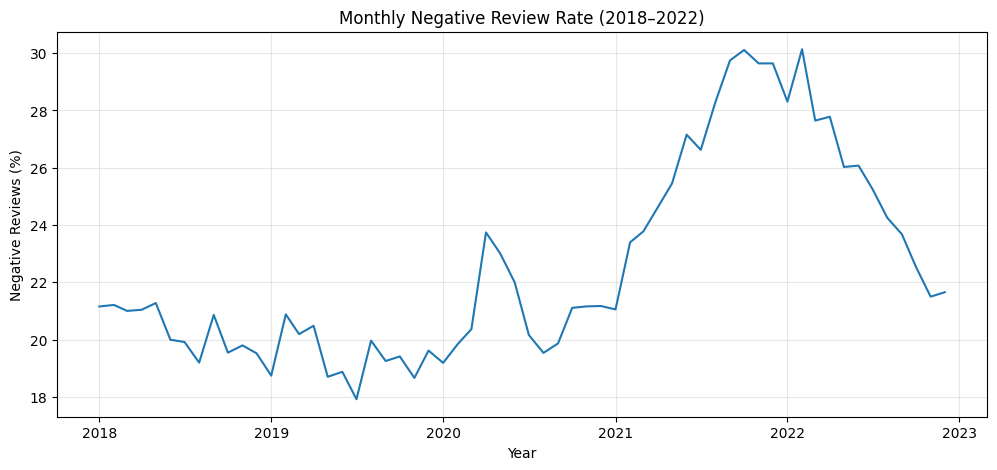

In [ ]:

# Step 9: Monthly Negative Review Analysis

import matplotlib.pyplot as plt

# Select complete years: 2018–2022
period_data = df_clean[
    (df_clean["review_date"] >= "2018-01-01") &
    (df_clean["review_date"] < "2023-01-01")
].copy()

# Aggregate monthly reviews
monthly_stats = (
    period_data
    .set_index("review_date")
    .resample("MS")
    .agg(
        total_reviews=("rating", "size"),
        negative_reviews=("is_negative", "sum")
    )
)

# Calculate monthly negative percentage
monthly_stats["negative_percentage"] = (
    monthly_stats["negative_reviews"]
    / monthly_stats["total_reviews"].replace(0, float("nan"))
    * 100
)

print("Total Months:", len(monthly_stats))
print("Months without Reviews:",
      (monthly_stats["total_reviews"] == 0).sum())

print("\nMonthly Statistics:")
print(monthly_stats.head())

# Visualize monthly negative review rate
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_stats.index,
    monthly_stats["negative_percentage"]
)

plt.title("Monthly Negative Review Rate (2018–2022)")
plt.xlabel("Year")
plt.ylabel("Negative Reviews (%)")
plt.grid(alpha=0.3)
plt.show()


year    2018   2019   2020   2021   2022
month                                   
1      21.16  18.74  19.19  21.05  28.31
2      21.21  20.88  19.84  23.40  30.14
3      21.00  20.19  20.37  23.78  27.65
4      21.04  20.48  23.74  24.62  27.78
5      21.28  18.70  23.01  25.45  26.03
6      20.00  18.88  22.00  27.15  26.07
7      19.92  17.92  20.16  26.62  25.24
8      19.20  19.96  19.54  28.29  24.25
9      20.86  19.25  19.87  29.74  23.68
10     19.55  19.41  21.11  30.11  22.53
11     19.80  18.66  21.16  29.64  21.50
12     19.52  19.62  21.17  29.64  21.65


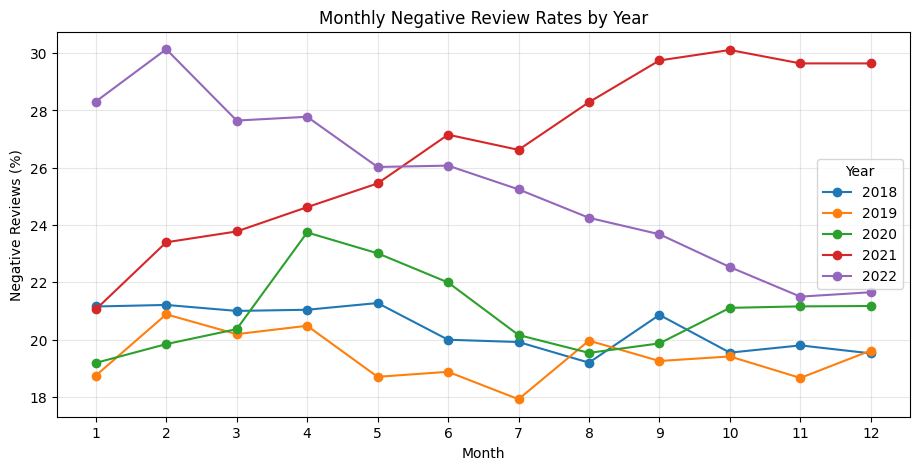

In [ ]:

# Step 10: Explore Monthly Seasonality

# Prepare monthly rates by year and month
seasonality_data = monthly_stats[
    ["negative_percentage"]
].copy()

seasonality_data["year"] = (
    seasonality_data.index.year
)

seasonality_data["month"] = (
    seasonality_data.index.month
)

# Compare the same months across years
seasonal_table = seasonality_data.pivot(
    index="month",
    columns="year",
    values="negative_percentage"
)

print(seasonal_table.round(2))

# Plot one line for each year
import matplotlib.pyplot as plt

seasonal_table.plot(
    figsize=(11, 5),
    marker="o"
)

plt.title("Monthly Negative Review Rates by Year")
plt.xlabel("Month")
plt.ylabel("Negative Reviews (%)")
plt.xticks(range(1, 13))
plt.legend(title="Year")
plt.grid(alpha=0.3)
plt.show()


Training Months: 48
Testing Months: 12

Forecast Accuracy:
Baseline MAE: 4.321
Baseline RMSE: 4.998
ARIMA MAE: 4.227
ARIMA RMSE: 4.916


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


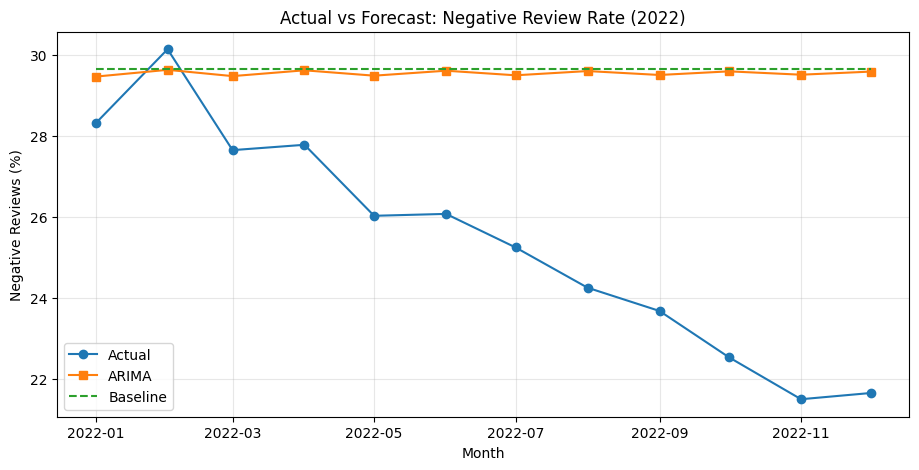

In [ ]:

# Step 11: ARIMA vs Baseline (Initial Experiment)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA

# 1. Prepare training and testing data
series = monthly_stats["negative_percentage"]

train = series.loc["2018":"2021"]
test = series.loc["2022"]

print("Training Months:", len(train))
print("Testing Months:", len(test))

# 2. Naive baseline: repeat the last training value
baseline_forecast = pd.Series(
    np.full(len(test), train.iloc[-1]),
    index=test.index
)

# 3. Fit an initial ARIMA model
model = ARIMA(train, order=(1, 1, 1))
model_fit = model.fit()

arima_forecast = model_fit.forecast(steps=len(test))
arima_forecast.index = test.index

# 4. Calculate evaluation metrics
def evaluate(actual, predicted):
    mae = np.mean(np.abs(actual - predicted))
    rmse = np.sqrt(np.mean((actual - predicted) ** 2))
    return mae, rmse

baseline_mae, baseline_rmse = evaluate(
    test, baseline_forecast
)

arima_mae, arima_rmse = evaluate(
    test, arima_forecast
)

print("\nForecast Accuracy:")
print("Baseline MAE:", round(baseline_mae, 3))
print("Baseline RMSE:", round(baseline_rmse, 3))
print("ARIMA MAE:", round(arima_mae, 3))
print("ARIMA RMSE:", round(arima_rmse, 3))

# 5. Plot actual and forecasted values
plt.figure(figsize=(11, 5))

plt.plot(test.index, test, label="Actual", marker="o")
plt.plot(test.index, arima_forecast,
         label="ARIMA", marker="s")
plt.plot(test.index, baseline_forecast,
         label="Baseline", linestyle="--")

plt.title("Actual vs Forecast: Negative Review Rate (2022)")
plt.xlabel("Month")
plt.ylabel("Negative Reviews (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [ ]:

# Step 12: Check ARIMA Model Convergence

print("ARIMA Model Diagnostics")

print(
    "Converged:",
    model_fit.mle_retvals.get("converged")
)

print(
    "Model AIC:",
    round(model_fit.aic, 3)
)

print(
    "Model BIC:",
    round(model_fit.bic, 3)
)


ARIMA Model Diagnostics
Converged: True
Model AIC: 144.332
Model BIC: 149.882


In [ ]:

# Step 13: ARIMA Residual Diagnostics

from statsmodels.stats.diagnostic import acorr_ljungbox

# Get model residuals
residuals = model_fit.resid.dropna()

# Exclude initial residual affected by initialization
residuals = residuals.iloc[1:]

# Ljung-Box test
lb_test = acorr_ljungbox(
    residuals,
    lags=[6, 12],
    return_df=True
)

print("Ljung-Box Test Results:")
print(lb_test)


Ljung-Box Test Results:
     lb_stat  lb_pvalue
6   3.784893   0.705759
12  5.158043   0.952491


In [ ]:

# Step 14: ARIMA Model Selection

import numpy as np
import pandas as pd
from statsmodels.tsa.arima.model import ARIMA

# Use 2018–2020 to train
selection_train = series.loc[
    "2018-01":"2020-12"
]

# Use 2021 to validate
validation = series.loc[
    "2021-01":"2021-12"
]

# Candidate ARIMA models
orders = [
    (1, 1, 0),
    (0, 1, 1),
    (1, 1, 1),
    (2, 1, 0)
]

results = []

for order in orders:
    model = ARIMA(
        selection_train,
        order=order
    )

    fitted = model.fit()

    # Check convergence
    if not fitted.mle_retvals.get(
        "converged", False
    ):
        print("Not converged:", order)
        continue

    # Forecast 12 months
    forecast = fitted.forecast(
        steps=len(validation)
    )

    actual = validation.to_numpy()
    predicted = np.asarray(forecast)

    mae = np.mean(
        np.abs(actual - predicted)
    )

    rmse = np.sqrt(
        np.mean((actual - predicted) ** 2)
    )

    results.append({
        "Model": str(order),
        "MAE": round(mae, 3),
        "RMSE": round(rmse, 3),
        "AIC": round(fitted.aic, 3)
    })

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    "MAE"
)

print("ARIMA Model Comparison:")
print(comparison_df.to_string(index=False))


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


ARIMA Model Comparison:
    Model   MAE  RMSE     AIC
(2, 1, 0) 5.466 6.150 109.513
(1, 1, 0) 5.473 6.157 108.129
(0, 1, 1) 5.488 6.173 108.279
(1, 1, 1) 5.528 6.219 107.130


In [ ]:

# Step 15: Compare ARIMA with Baselines

import numpy as np
import pandas as pd

# Actual validation data (2021)
actual = validation.to_numpy()

# Baseline 1: Last observed value (Dec 2020)
naive_forecast = np.repeat(
    selection_train.iloc[-1],
    len(validation)
)

# Baseline 2: Same month from 2020
seasonal_naive = (
    selection_train.iloc[-12:]
    .to_numpy()
)

# Evaluation function
def calculate_metrics(actual, predicted):
    mae = np.mean(np.abs(actual - predicted))
    rmse = np.sqrt(
        np.mean((actual - predicted) ** 2)
    )
    return round(mae, 3), round(rmse, 3)

# Compare results
baseline_results = pd.DataFrame([
    {
        "Model": "Naive Baseline",
        "MAE": calculate_metrics(
            actual, naive_forecast
        )[0],
        "RMSE": calculate_metrics(
            actual, naive_forecast
        )[1]
    },
    {
        "Model": "Seasonal Naive",
        "MAE": calculate_metrics(
            actual, seasonal_naive
        )[0],
        "RMSE": calculate_metrics(
            actual, seasonal_naive
        )[1]
    }
])

print("Baseline Results (2021):")
print(baseline_results.to_string(index=False))

print("\nBest ARIMA Candidate:")
print(
    comparison_df[
        ["Model", "MAE", "RMSE"]
    ].head(1).to_string(index=False)
)


Baseline Results (2021):
         Model   MAE  RMSE
Naive Baseline 5.471 6.155
Seasonal Naive 5.695 6.464

Best ARIMA Candidate:
    Model   MAE  RMSE
(2, 1, 0) 5.466  6.15


Model Converged: True

2022 Forecast Results:
         Model   MAE  RMSE
  ARIMA(2,1,0) 4.227 4.903
Naive Baseline 4.321 4.998


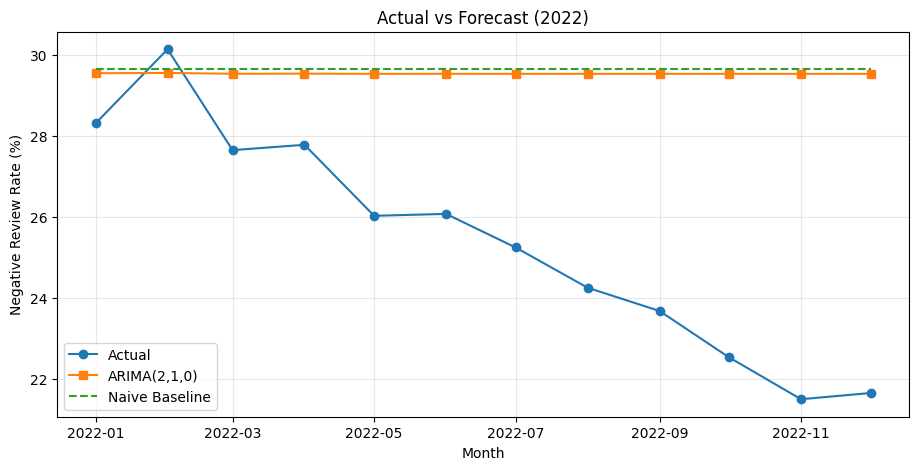

In [ ]:

# Step 16: Evaluate Selected ARIMA on 2022

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA

# Training: 2018–2021
final_train = series.loc["2018-01":"2021-12"]

# Evaluation: 2022
final_test = series.loc["2022-01":"2022-12"]

# Selected ARIMA model
final_model = ARIMA(
    final_train,
    order=(2, 1, 0)
)

final_fit = final_model.fit()

# Forecast 12 months
final_forecast = final_fit.forecast(
    steps=len(final_test)
)

# Naive baseline
final_baseline = np.repeat(
    final_train.iloc[-1],
    len(final_test)
)

# Evaluation
def forecast_metrics(actual, predicted):
    actual = np.asarray(actual)
    predicted = np.asarray(predicted)

    mae = np.mean(np.abs(actual - predicted))
    rmse = np.sqrt(np.mean((actual - predicted)**2))

    return round(mae, 3), round(rmse, 3)

results = pd.DataFrame([
    {
        "Model": "ARIMA(2,1,0)",
        "MAE": forecast_metrics(
            final_test, final_forecast
        )[0],
        "RMSE": forecast_metrics(
            final_test, final_forecast
        )[1]
    },
    {
        "Model": "Naive Baseline",
        "MAE": forecast_metrics(
            final_test, final_baseline
        )[0],
        "RMSE": forecast_metrics(
            final_test, final_baseline
        )[1]
    }
])

print("Model Converged:",
      final_fit.mle_retvals.get("converged"))

print("\n2022 Forecast Results:")
print(results.to_string(index=False))

# Visualization
plt.figure(figsize=(11, 5))

plt.plot(
    final_test.index, final_test,
    label="Actual", marker="o"
)

plt.plot(
    final_test.index, final_forecast,
    label="ARIMA(2,1,0)", marker="s"
)

plt.plot(
    final_test.index, final_baseline,
    label="Naive Baseline", linestyle="--"
)

plt.title("Actual vs Forecast (2022)")
plt.xlabel("Month")
plt.ylabel("Negative Review Rate (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


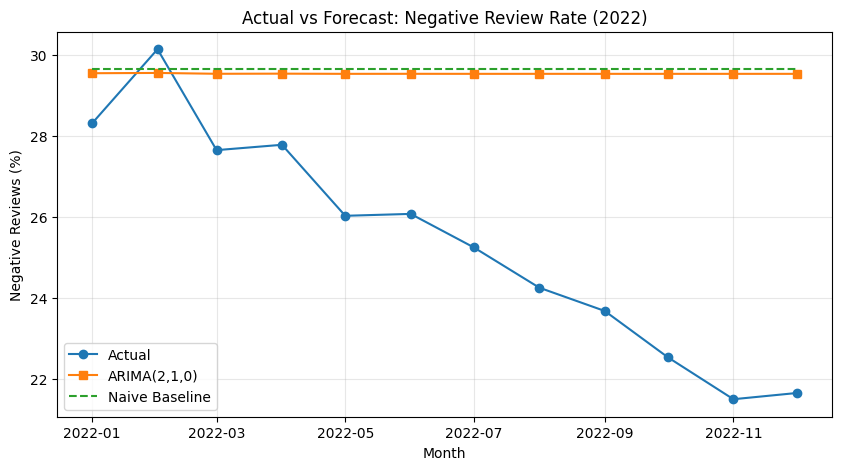

Table 6 and Figure 5 saved successfully!


In [ ]:

# Step 17: Save Table 6 and Figure 5

from pathlib import Path
import matplotlib.pyplot as plt

# Create results folder
output_dir = Path(
    "/content/drive/MyDrive/Big data project/Results"
)
output_dir.mkdir(parents=True, exist_ok=True)

# Save Table 6
results.to_csv(
    output_dir / "T6_Forecast_Accuracy.csv",
    index=False
)

# Save Figure 5
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    final_test.index,
    final_test.values,
    label="Actual",
    marker="o"
)

ax.plot(
    final_test.index,
    final_forecast.values,
    label="ARIMA(2,1,0)",
    marker="s"
)

ax.plot(
    final_test.index,
    final_baseline,
    label="Naive Baseline",
    linestyle="--"
)

ax.set_title(
    "Actual vs Forecast: Negative Review Rate (2022)"
)
ax.set_xlabel("Month")
ax.set_ylabel("Negative Reviews (%)")
ax.legend()
ax.grid(alpha=0.3)

fig.savefig(
    output_dir / "F5_Actual_vs_Forecast.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Table 6 and Figure 5 saved successfully!")


In [ ]:

# Step 18: MapReduce Concept - Word Count

import re
from collections import Counter

# Select 1,000 reviews
sample = df_clean["text"].head(1000)

# MAP: Generate (word, 1) pairs
mapped_pairs = []

for review in sample:
    words = re.findall(
        r"[a-z]+", review.lower()
    )

    for word in words:
        mapped_pairs.append((word, 1))

# REDUCE: Sum counts for each word
word_counts = Counter()

for word, count in mapped_pairs:
    word_counts[word] += count

# Display top 10 words
print("Top 10 Most Frequent Words:")
for word, count in word_counts.most_common(10):
    print(word, ":", count)


Top 10 Most Frequent Words:
the : 3567
i : 3239
and : 2535
it : 2477
a : 2398
to : 2227
br : 1803
is : 1738
this : 1473
of : 1368


In [ ]:

# Step 19: Cleaned Word Frequency

import re
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# Stop words + HTML artifact
stop_words = set(ENGLISH_STOP_WORDS)
stop_words.add("br")

clean_word_counts = Counter()

# Use the same 1,000 reviews
for review in sample:

    words = re.findall(
        r"[a-z]+",
        str(review).lower()
    )

    clean_words = [
        word for word in words
        if word not in stop_words
        and len(word) > 2
    ]

    clean_word_counts.update(clean_words)

print("Top 15 Meaningful Words:\n")

for word, count in clean_word_counts.most_common(15):
    print(word, ":", count)


Top 15 Meaningful Words:

skin : 707
hair : 546
use : 514
like : 467
great : 306
just : 292
good : 283
product : 270
really : 246
love : 228
nice : 226
face : 216
used : 209
little : 204
using : 194


In [ ]:

%%writefile mapper.py

import sys
import re
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

stop_words = set(ENGLISH_STOP_WORDS)
stop_words.add("br")

for line in sys.stdin:
    words = re.findall(r"[a-z]+", line.lower())

    for word in words:
        if word not in stop_words and len(word) > 2:
            print(f"{word}\t1")


Writing mapper.py


In [ ]:

%%writefile reducer.py

import sys

current_word = None
current_count = 0

for line in sys.stdin:

    line = line.strip()

    try:
        word, count = line.split("\t", 1)
        count = int(count)
    except ValueError:
        continue

    if word == current_word:
        current_count += count

    else:
        if current_word is not None:
            print(f"{current_word}\t{current_count}")

        current_word = word
        current_count = count

# Print the last word
if current_word is not None:
    print(f"{current_word}\t{current_count}")


Writing reducer.py


In [ ]:

# Step 22: Run Mapper + Sort + Reducer

import subprocess
from collections import Counter

# 1. Save the same 1,000 reviews as text
with open("reviews_sample.txt", "w", encoding="utf-8") as f:
    for review in sample:
        review = str(review).replace("\n", " ").replace("\r", " ")
        f.write(review + "\n")

# 2. Run the local MapReduce-style pipeline
command = (
    "python mapper.py < reviews_sample.txt "
    "| LC_ALL=C sort "
    "| python reducer.py > wordcount_output.tsv"
)

subprocess.run(
    ["bash", "-o", "pipefail", "-c", command],
    check=True
)

# 3. Read the results
result_counts = Counter()

with open("wordcount_output.tsv", encoding="utf-8") as f:
    for line in f:
        word, count = line.strip().split("\t")
        result_counts[word] = int(count)

# 4. Display results
print("Top 15 Words from Mapper + Reducer:\n")

for word, count in result_counts.most_common(15):
    print(word, ":", count)

# 5. Verify against Step 19
print("\nMatches previous Word Count:",
      result_counts == clean_word_counts)


Top 15 Words from Mapper + Reducer:

skin : 707
hair : 546
use : 514
like : 467
great : 306
just : 292
good : 283
product : 270
really : 246
love : 228
nice : 226
face : 216
used : 209
little : 204
using : 194

Matches previous Word Count: True


In [ ]:

# Step 23: Save MapReduce and HiveQL Files

from pathlib import Path
import shutil

output = Path(
    "/content/drive/MyDrive/Big data project/Scalability"
)
output.mkdir(parents=True, exist_ok=True)

# Save previously tested scripts and input
for filename in [
    "mapper.py",
    "reducer.py",
    "reviews_sample.txt"
]:
    shutil.copy(filename, output / filename)

# Save the same stop-word list used in Python
(output / "stopwords.txt").write_text(
    "\n".join(sorted(stop_words)) + "\n",
    encoding="utf-8"
)

# HiveQL alternative
hive_query = r"""
CREATE EXTERNAL TABLE IF NOT EXISTS beauty_reviews (
    review_text STRING
)
STORED AS TEXTFILE
LOCATION '/user/bigdata/beauty/reviews/';

CREATE EXTERNAL TABLE IF NOT EXISTS stopword_list (
    word STRING
)
STORED AS TEXTFILE
LOCATION '/user/bigdata/beauty/stopwords/';

WITH tokens AS (
    SELECT word
    FROM beauty_reviews
    LATERAL VIEW explode(
        split(lower(review_text), '[^a-z]+')
    ) e AS word
)
SELECT t.word, COUNT(*) AS frequency
FROM tokens t
LEFT JOIN stopword_list s
    ON t.word = s.word
WHERE LENGTH(t.word) > 2
  AND s.word IS NULL
GROUP BY t.word
ORDER BY frequency DESC
LIMIT 15;
"""

(output / "wordcount_hive.hql").write_text(
    hive_query,
    encoding="utf-8"
)

print("Files saved successfully!")
print("\nSaved files:")
for file in sorted(output.iterdir()):
    print("-", file.name)


Files saved successfully!

Saved files:
- mapper.py
- reducer.py
- reviews_sample.txt
- stopwords.txt
- wordcount_hive.hql


In [ ]:

# Step 24: Scalability Capacity Estimation

# Current number of cleaned reviews
current_reviews = len(df_clean)

# Hypothetical 1000x growth
scale_factor = 1000
future_reviews = current_reviews * scale_factor

# Measure UTF-8 text storage in bytes
text_bytes = sum(
    len(str(text).encode("utf-8"))
    for text in df_clean["text"]
)

# Estimate scaled storage
future_bytes = text_bytes * scale_factor

# HDFS replication factor
replication_factor = 3
hdfs_bytes = future_bytes * replication_factor

# Convert to GiB
gib = 1024 ** 3

print("SCALABILITY ESTIMATION")
print("-" * 40)

print(f"Current Reviews: {current_reviews:,}")
print(f"Future Reviews (1000x): {future_reviews:,}")

print(f"\nCurrent Text Size: {text_bytes/gib:.3f} GiB")
print(f"Future Text Size: {future_bytes/gib:.2f} GiB")

print(
    f"HDFS Storage (3 replicas): "
    f"{hdfs_bytes/gib:.2f} GiB"
)

print("\nNote: Text payload only; estimates exclude")
print("metadata, file formats, indexes and overhead.")


SCALABILITY ESTIMATION
----------------------------------------
Current Reviews: 693,547
Future Reviews (1000x): 693,547,000

Current Text Size: 0.112 GiB
Future Text Size: 112.33 GiB
HDFS Storage (3 replicas): 336.99 GiB

Note: Text payload only; estimates exclude
metadata, file formats, indexes and overhead.


In [ ]:

# Restore Amazon Reviews Dataset

import pandas as pd
from pathlib import Path

# 1. Correct file path
file_path = Path(
    "/content/drive/MyDrive/Big data project/All_Beauty.jsonl"
)

# 2. Load original dataset
df = pd.read_json(
    file_path,
    lines=True
)

# 3. Remove duplicate reviews
duplicate_keys = [
    "user_id", "asin", "timestamp", "text"
]

df_clean = (
    df.sort_values(
        "helpful_vote",
        ascending=False,
        kind="stable"
    )
    .drop_duplicates(
        subset=duplicate_keys,
        keep="first"
    )
    .sort_index()
    .copy()
)

# 4. Remove empty review texts
df_clean["text"] = df_clean["text"].str.strip()

df_clean = df_clean[
    df_clean["text"].notna()
    & df_clean["text"].ne("")
].copy()

# 5. Verify
print("Original Reviews:", len(df))
print("Cleaned Reviews:", len(df_clean))
print("Cleaning Matches Previous Results:",
      len(df_clean) == 693547)


Original Reviews: 701528
Cleaned Reviews: 693547
Cleaning Matches Previous Results: True


In [ ]:

from pathlib import Path

# Project folder
folder = Path(
    "/content/drive/MyDrive/Big data project"
)

print("Project folder exists:", folder.exists())

print("\nDATASET FILES FOUND:")
print("-" * 50)

if folder.exists():

    files = [
        p for p in folder.rglob("*")
        if p.is_file()
        and (
            "beauty" in p.name.lower()
            or p.name.lower().endswith(
                (".jsonl.gz", ".json.gz", ".parquet")
            )
        )
    ]

    if files:
        for file in files[:30]:
            print(file)
    else:
        print("No matching dataset files found.")
        print("\nFiles in project folder:")
        for item in list(folder.iterdir())[:30]:
            print(item.name)

else:
    print("Project folder not found.")


Project folder exists: True

DATASET FILES FOUND:
--------------------------------------------------
/content/drive/MyDrive/Big data project/Amazon all beautyDS.ipynb
/content/drive/MyDrive/Big data project/All_Beauty.jsonl


In [ ]:

# Step 25: Estimate Full Record Storage

# Original review fields
original_columns = [
    "rating", "title", "text", "images",
    "asin", "parent_asin", "user_id",
    "timestamp", "helpful_vote",
    "verified_purchase"
]

# Random representative sample
records_sample = df_clean[
    original_columns
].sample(n=5000, random_state=42)

# Serialize sample as JSON Lines
sample_json = records_sample.to_json(
    orient="records",
    lines=True,
    force_ascii=False,
    date_format="iso"
)

# Measure serialized size
sample_bytes = len(
    sample_json.encode("utf-8")
)

average_record_bytes = (
    sample_bytes / len(records_sample)
)

# Project to 1000x growth
projected_records = len(df_clean) * 1000

estimated_total_bytes = (
    average_record_bytes * projected_records
)

estimated_hdfs_bytes = (
    estimated_total_bytes * 3
)

gib = 1024 ** 3

print("FULL RECORD STORAGE ESTIMATION")
print("-" * 40)

print(
    f"Average Record: "
    f"{average_record_bytes:.2f} bytes"
)

print(
    f"Projected Reviews: "
    f"{projected_records:,}"
)

print(
    f"Estimated Full Data: "
    f"{estimated_total_bytes/gib:.2f} GiB"
)

print(
    f"Estimated HDFS (3 replicas): "
    f"{estimated_hdfs_bytes/gib:.2f} GiB"
)

print("\nNote: Sample-based estimate;")
print("uncompressed JSON Lines, excluding")
print("HDFS metadata and processing overhead.")


FULL RECORD STORAGE ESTIMATION
----------------------------------------
Average Record: 458.73 bytes
Projected Reviews: 693,547,000
Estimated Full Data: 296.30 GiB
Estimated HDFS (3 replicas): 888.90 GiB

Note: Sample-based estimate;
uncompressed JSON Lines, excluding
HDFS metadata and processing overhead.


In [ ]:

# Step 26: Prepare Dataset for Hadoop

from pathlib import Path

project_dir = Path(
    "/content/drive/MyDrive/Big data project"
)

scalability_dir = project_dir / "Scalability"
scalability_dir.mkdir(parents=True, exist_ok=True)

# 1. Save the cleaned dataset
parquet_path = project_dir / "All_Beauty_clean.parquet"

df_clean.to_parquet(
    parquet_path,
    index=False
)

# 2. Prepare text input for Hadoop Streaming
hadoop_path = (
    scalability_dir / "reviews_for_hadoop.txt"
)

with open(hadoop_path, "w", encoding="utf-8") as f:
    for review in df_clean["text"]:
        clean_line = (
            str(review)
            .replace("\n", " ")
            .replace("\r", " ")
        )
        f.write(clean_line + "\n")

# 3. Verify saved files
print("DATASET EXPORT COMPLETED")
print("-" * 40)

print("Cleaned Reviews:", len(df_clean))
print("Parquet Saved:", parquet_path.exists())
print("Hadoop Input Saved:", hadoop_path.exists())

print(
    "Hadoop Input Size:",
    round(hadoop_path.stat().st_size / 1024**2, 2),
    "MiB"
)


DATASET EXPORT COMPLETED
----------------------------------------
Cleaned Reviews: 693547
Parquet Saved: True
Hadoop Input Saved: True
Hadoop Input Size: 115.69 MiB


In [ ]:

# Step 42: Start Association Rule Mining

import pandas as pd
from google.colab import drive

drive.mount("/content/drive")

file_path = (
    "/content/drive/MyDrive/Big data project/"
    "All_Beauty_clean.parquet"
)

df_clean = pd.read_parquet(file_path)

print("Dataset loaded successfully!")
print("Total reviews:", len(df_clean))
print("Columns:", df_clean.columns.tolist())

print("\nSample review:")
print(df_clean["text"].iloc[0][:500])


Mounted at /content/drive
Dataset loaded successfully!
Total reviews: 693547
Columns: ['rating', 'title', 'text', 'images', 'asin', 'parent_asin', 'user_id', 'timestamp', 'helpful_vote', 'verified_purchase']

Sample review:
This spray is really nice. It smells really good, goes on really fine, and does the trick. I will say it feels like you need a lot of it though to get the texture I want. I have a lot of hair, medium thickness. I am comparing to other brands with yucky chemicals so I'm gonna stick with this. Try it!


In [ ]:

# Step 43: Prepare review-level transactions

import re
from collections import Counter

beauty_terms = [
    "hair", "shampoo", "conditioner", "scalp",
    "skin", "face", "moisturizer", "cream",
    "lotion", "serum", "acne", "dry",
    "oily", "scent", "smell", "fragrance",
    "soft", "smooth", "sticky", "greasy",
    "price", "expensive", "cheap", "quality",
    "packaging", "broken", "leak", "delivery",
    "love", "great", "good", "bad",
    "disappointed", "recommend", "return"
]

terms_set = set(beauty_terms)

def extract_transaction(text):
    words = set(
        re.findall(r"[a-z]+", str(text).lower())
    )
    return sorted(words.intersection(terms_set))

transactions = df_clean["text"].map(
    extract_transaction
)

term_counts = Counter(
    term
    for transaction in transactions
    for term in transaction
)

print("Total reviews:", len(transactions))
print("Reviews with selected terms:",
      sum(bool(t) for t in transactions))
print("\nTop 20 terms by review frequency:")

for term, count in term_counts.most_common(20):
    print(f"{term:15s} {count:>8,}")


Total reviews: 693547
Reviews with selected terms: 451049

Top 20 terms by review frequency:
great            119,836
love             111,340
hair             103,515
good              85,033
skin              45,193
price             40,302
quality           39,019
soft              34,757
recommend         33,984
smell             26,765
face              24,082
dry               23,975
scent             19,392
bad               13,425
smooth            13,154
disappointed      13,088
cheap             11,102
cream              9,143
shampoo            8,315
expensive          8,218


In [ ]:

# Step 44: Frequent Itemset Mining with FP-Growth

!pip -q install mlxtend

import pandas as pd
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import fpgrowth

# Convert review transactions into a binary matrix
te = TransactionEncoder()
encoded = te.fit(transactions).transform(transactions)

transaction_df = pd.DataFrame(
    encoded,
    columns=te.columns_
)

print("Transaction matrix:", transaction_df.shape)

# Mine frequent itemsets
frequent_itemsets = fpgrowth(
    transaction_df,
    min_support=0.005,
    use_colnames=True,
    max_len=3
)

# Count the number of terms in each itemset
frequent_itemsets["length"] = (
    frequent_itemsets["itemsets"].apply(len)
)

frequent_itemsets = frequent_itemsets.sort_values(
    "support", ascending=False
).reset_index(drop=True)

print("\nTotal frequent itemsets:", len(frequent_itemsets))

# Show frequently co-occurring pairs
pairs = frequent_itemsets[
    frequent_itemsets["length"] == 2
].copy()

pairs["terms"] = pairs["itemsets"].apply(
    lambda x: " + ".join(sorted(x))
)

print("\nTop 15 frequent pairs:")
print(
    pairs[["terms", "support"]]
    .head(15)
    .to_string(index=False)
)


In [ ]:

# Step 44: FP-Growth - clean output

import warnings
warnings.filterwarnings(
    "ignore",
    category=DeprecationWarning,
    message=r"datetime\.datetime\.utcnow\(\) is deprecated.*"
)

from mlxtend.frequent_patterns import fpgrowth

# Extract frequent itemsets
frequent_itemsets = fpgrowth(
    transaction_df,
    min_support=0.005,
    use_colnames=True,
    max_len=3
)

frequent_itemsets["length"] = (
    frequent_itemsets["itemsets"].apply(len)
)

# Keep pairs only
pairs = frequent_itemsets[
    frequent_itemsets["length"] == 2
].copy()

pairs["terms"] = pairs["itemsets"].apply(
    lambda x: " + ".join(sorted(x))
)

pairs = pairs.sort_values(
    "support", ascending=False
)

print("Total frequent itemsets:", len(frequent_itemsets))
print("Total frequent pairs:", len(pairs))

display(pairs[["terms", "support"]].head(15))


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Total frequent itemsets: 82
Total frequent pairs: 49


,terms,support
31,great + hair,0.028462
48,great + love,0.028334
32,hair + love,0.028075
34,good + hair,0.021671
70,great + price,0.021306
78,good + quality,0.019500
38,hair + soft,0.018499
35,good + great,0.017751
74,great + quality,0.016283
73,good + price,0.015633


In [ ]:

# Step 45: Generate Association Rules

from mlxtend.frequent_patterns import association_rules

rules = association_rules(
    frequent_itemsets,
    num_itemsets=len(transaction_df),
    metric="confidence",
    min_threshold=0.10
)

# Select positively associated rules
strong_rules = rules[
    (rules["lift"] > 1.0) &
    (rules["confidence"] >= 0.15)
].copy()

# Make word combinations readable
def format_terms(items):
    return ", ".join(sorted(items))

strong_rules["IF"] = (
    strong_rules["antecedents"].apply(format_terms)
)

strong_rules["THEN"] = (
    strong_rules["consequents"].apply(format_terms)
)

strong_rules = strong_rules.sort_values(
    ["lift", "confidence"],
    ascending=False
).reset_index(drop=True)

print("Total generated rules:", len(rules))
print("Rules passing selected filters:", len(strong_rules))

display(
    strong_rules[
        ["IF", "THEN", "support", "confidence", "lift"]
    ].head(15).round(4)
)


Total generated rules: 70
Rules passing selected filters: 58


,IF,THEN,support,confidence,lift
0,cream,skin,0.0051,0.3848,5.9049
1,face,skin,0.0118,0.3392,5.2051
2,skin,face,0.0118,0.1807,5.2051
3,smooth,skin,0.0061,0.3232,4.9595
4,conditioner,hair,0.0065,0.7278,4.8765
5,dry,skin,0.0109,0.3165,4.8564
6,skin,dry,0.0109,0.1679,4.8564
7,shampoo,hair,0.0077,0.6427,4.3060
8,"hair, love",soft,0.0051,0.1809,3.6104
9,scent,skin,0.0058,0.2082,3.1956


In [ ]:

# Step 46: Save Association Rule Mining Results

from pathlib import Path
import pandas as pd

output_dir = Path(
    "/content/drive/MyDrive/Big data project/"
    "03_Association_Rules"
)

output_dir.mkdir(parents=True, exist_ok=True)

# 1. Save all selected association rules
rules_export = strong_rules[
    ["IF", "THEN", "support", "confidence", "lift"]
].copy()

rules_export.to_csv(
    output_dir / "Association_Rules_All.csv",
    index=False
)

# 2. Save top 10 rules for the paper
top10 = rules_export.head(10).copy()

top10["support"] = (
    top10["support"] * 100
).round(2)

top10["confidence"] = (
    top10["confidence"] * 100
).round(2)

top10["lift"] = top10["lift"].round(2)

top10.columns = [
    "Antecedent",
    "Consequent",
    "Support (%)",
    "Confidence (%)",
    "Lift"
]

top10.to_csv(
    output_dir / "Table3_Association_Rules.csv",
    index=False
)

# 3. Save frequent itemsets
itemsets_export = frequent_itemsets.copy()

itemsets_export["itemsets"] = (
    itemsets_export["itemsets"].apply(
        lambda x: ", ".join(sorted(x))
    )
)

itemsets_export.to_csv(
    output_dir / "Frequent_Itemsets.csv",
    index=False
)

print("Files saved successfully!")
print("Location:", output_dir)

print("\nTable 3 — Association Rules:")
display(top10)


Files saved successfully!
Location: /content/drive/MyDrive/Big data project/03_Association_Rules

Table 3 — Association Rules:


,Antecedent,Consequent,Support (%),Confidence (%),Lift
0,cream,skin,0.51,38.48,5.90
1,face,skin,1.18,33.92,5.21
2,skin,face,1.18,18.07,5.21
3,smooth,skin,0.61,32.32,4.96
4,conditioner,hair,0.65,72.78,4.88
5,dry,skin,1.09,31.65,4.86
6,skin,dry,1.09,16.79,4.86
7,shampoo,hair,0.77,64.27,4.31
8,"hair, love",soft,0.51,18.09,3.61
9,scent,skin,0.58,20.82,3.20


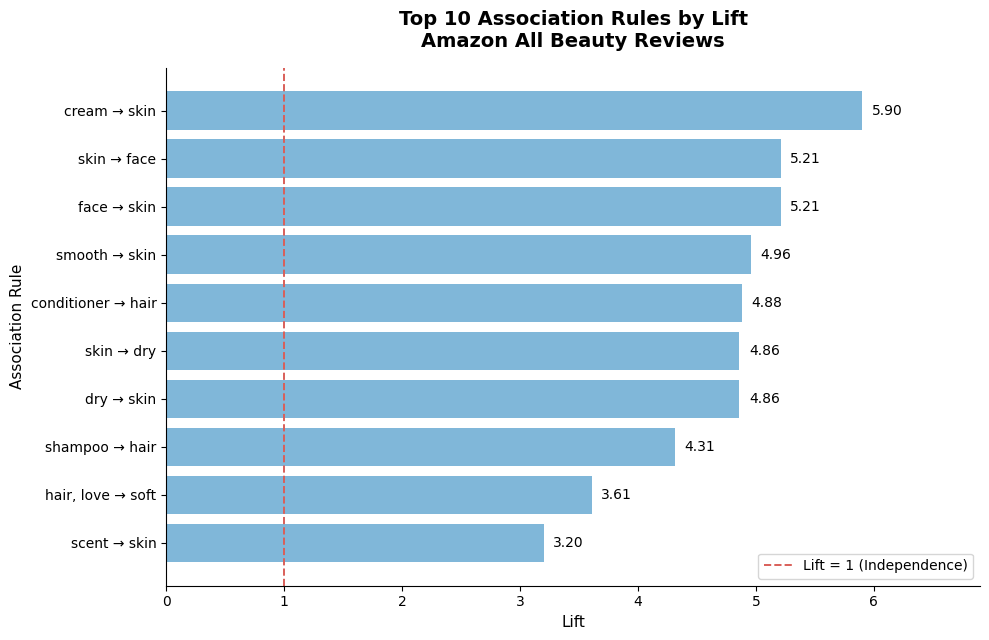

Figure saved successfully!


In [ ]:

# Step 47: Visualize and Save Association Rules

import matplotlib.pyplot as plt
from pathlib import Path

output_dir = Path(
    "/content/drive/MyDrive/Big data project/"
    "03_Association_Rules"
)

# Use the actual Table 3 results
plot_data = top10.copy()

plot_data["Rule"] = (
    plot_data["Antecedent"]
    + " → "
    + plot_data["Consequent"]
)

plot_data = plot_data.sort_values("Lift")

fig, ax = plt.subplots(figsize=(10, 6.5))

bars = ax.barh(
    plot_data["Rule"],
    plot_data["Lift"],
    color="#80B7D9"
)

# Add values next to each bar
for bar in bars:
    value = bar.get_width()
    ax.text(
        value + 0.08,
        bar.get_y() + bar.get_height()/2,
        f"{value:.2f}",
        va="center",
        fontsize=10
    )

ax.axvline(
    x=1,
    color="#D95F59",
    linestyle="--",
    linewidth=1.4,
    label="Lift = 1 (Independence)"
)

ax.set_xlim(0, plot_data["Lift"].max() + 1)
ax.set_xlabel("Lift", fontsize=11)
ax.set_ylabel("Association Rule", fontsize=11)
ax.set_title(
    "Top 10 Association Rules by Lift\n"
    "Amazon All Beauty Reviews",
    fontsize=14,
    weight="bold",
    pad=15
)

ax.legend(loc="lower right")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

# Save publication-quality files
plt.savefig(
    output_dir / "Association_Rules_Lift.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    output_dir / "Association_Rules_Lift.pdf",
    bbox_inches="tight"
)

plt.show()

print("Figure saved successfully!")


In [ ]:

# Step 48: Prepare Text Features for K-means

import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import Normalizer

# 1. Select a reproducible random sample
df_cluster = df_clean[
    df_clean["text"].notna()
    & df_clean["text"].astype(str).str.strip().ne("")
].sample(
    n=30000,
    random_state=42
).copy()

print("Sample size:", len(df_cluster))

# 2. Convert text into TF-IDF features
tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=8000,
    min_df=10,
    max_df=0.85,
    sublinear_tf=True
)

X_tfidf = tfidf.fit_transform(
    df_cluster["text"].astype(str)
)

print("TF-IDF matrix:", X_tfidf.shape)

# 3. Reduce dimensionality
svd = TruncatedSVD(
    n_components=50,
    random_state=42
)

X_reduced = svd.fit_transform(X_tfidf)

# 4. Normalize vectors for clustering
X_cluster = Normalizer().fit_transform(
    X_reduced
)

print("Reduced matrix:", X_cluster.shape)

print(
    "Explained variance:",
    round(svd.explained_variance_ratio_.sum() * 100, 2),
    "%"
)


Sample size: 30000
TF-IDF matrix: (30000, 3789)
Reduced matrix: (30000, 50)
Explained variance: 21.68 %


K=2 | Inertia=25772.00 | Silhouette=0.0361
K=3 | Inertia=25041.71 | Silhouette=0.0445
K=4 | Inertia=24391.01 | Silhouette=0.0462
K=5 | Inertia=23602.96 | Silhouette=0.0593
K=6 | Inertia=23492.69 | Silhouette=0.0486
K=7 | Inertia=22569.66 | Silhouette=0.0663
K=8 | Inertia=22171.15 | Silhouette=0.0661

K Evaluation Results:


,K,Inertia,Silhouette
0,2,25772.0035,0.0361
1,3,25041.7132,0.0445
2,4,24391.0074,0.0462
3,5,23602.9585,0.0593
4,6,23492.6859,0.0486
5,7,22569.6629,0.0663
6,8,22171.1524,0.0661


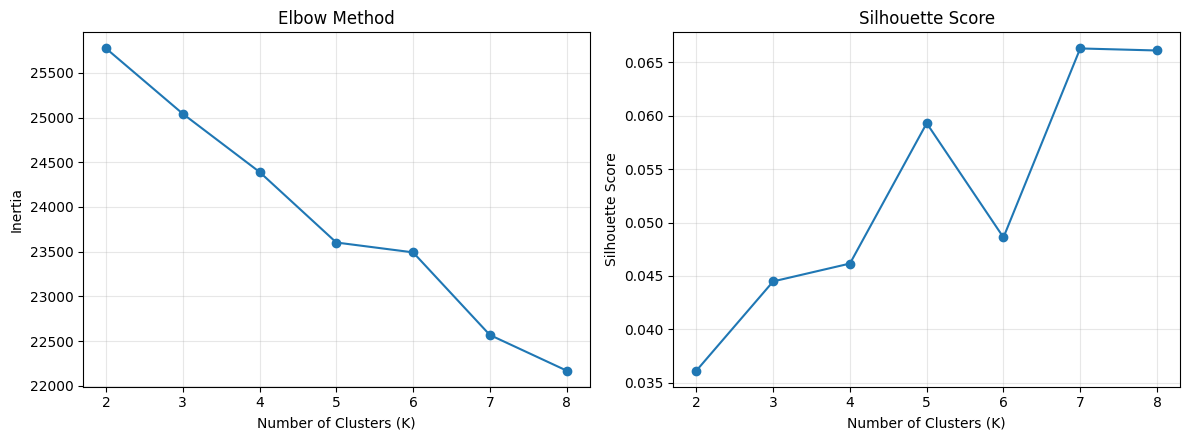

Best K by sampled Silhouette: 7


In [ ]:

# Step 49: Select K using Elbow and Silhouette

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score

k_values = range(2, 9)

results = []

for k in k_values:

    model = MiniBatchKMeans(
        n_clusters=k,
        random_state=42,
        batch_size=2048,
        n_init=5,
        max_iter=100
    )

    labels = model.fit_predict(X_cluster)

    # Evaluate silhouette on a reproducible sample
    silhouette = silhouette_score(
        X_cluster,
        labels,
        sample_size=2000,
        random_state=42
    )

    results.append({
        "K": k,
        "Inertia": model.inertia_,
        "Silhouette": silhouette
    })

    print(
        f"K={k} | "
        f"Inertia={model.inertia_:.2f} | "
        f"Silhouette={silhouette:.4f}"
    )

k_results = pd.DataFrame(results)

print("\nK Evaluation Results:")
display(k_results.round(4))

# Plot evaluation metrics
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(
    k_results["K"],
    k_results["Inertia"],
    marker="o"
)

axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")
axes[0].grid(alpha=0.3)

axes[1].plot(
    k_results["K"],
    k_results["Silhouette"],
    marker="o"
)

axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

best_k = int(
    k_results.loc[
        k_results["Silhouette"].idxmax(), "K"
    ]
)

print("Best K by sampled Silhouette:", best_k)


In [ ]:

# Step 50: Train and Interpret K-means Clusters

import numpy as np
import pandas as pd
from sklearn.cluster import MiniBatchKMeans

# 1. Train K-means with K=7
final_k = 7

kmeans_model = MiniBatchKMeans(
    n_clusters=final_k,
    random_state=42,
    batch_size=2048,
    n_init=5,
    max_iter=100
)

cluster_labels = kmeans_model.fit_predict(X_cluster)

# 2. Attach cluster labels to reviews
df_cluster = df_cluster.reset_index(drop=True).copy()
df_cluster["cluster"] = cluster_labels

# 3. Count reviews per cluster
cluster_sizes = (
    df_cluster["cluster"]
    .value_counts()
    .sort_index()
)

print("Cluster sizes:")
for cluster_id, count in cluster_sizes.items():
    percentage = count / len(df_cluster) * 100
    print(
        f"Cluster {cluster_id}: "
        f"{count:,} reviews ({percentage:.2f}%)"
    )

# 4. Approximate top words using SVD projection
centroids_tfidf = svd.inverse_transform(
    kmeans_model.cluster_centers_
)

feature_names = tfidf.get_feature_names_out()

print("\nTop 10 words per cluster:")

for cluster_id in range(final_k):
    top_indices = np.argsort(
        centroids_tfidf[cluster_id]
    )[-10:][::-1]

    top_words = feature_names[top_indices]

    print(
        f"Cluster {cluster_id}: "
        + ", ".join(top_words)
    )

# 5. Show one real review example per cluster
print("\nExample reviews:")

for cluster_id in range(final_k):
    subset = df_cluster[
        df_cluster["cluster"] == cluster_id
    ]

    example = subset.iloc[0]["text"]

    print(f"\n--- Cluster {cluster_id} ---")
    print(str(example)[:350])


Cluster sizes:
Cluster 0: 2,570 reviews (8.57%)
Cluster 1: 6,764 reviews (22.55%)
Cluster 2: 3,712 reviews (12.37%)
Cluster 3: 2,031 reviews (6.77%)
Cluster 4: 2,820 reviews (9.40%)
Cluster 5: 4,080 reviews (13.60%)
Cluster 6: 8,023 reviews (26.74%)

Top 10 words per cluster:
Cluster 0: love, product, use, color, great, easy, smell, scent, colors, perfect
Cluster 1: br, product, bought, used, time, did, use, didn, don, came
Cluster 2: hair, soft, like, love, great, use, product, long, good, really
Cluster 3: just, like, little, right, use, love, great, wanted, don, described
Cluster 4: great, product, works, price, use, quality, easy, love, work, value
Cluster 5: skin, use, recommend, used, using, br, works, face, doesn, product
Cluster 6: good, like, nice, easy, quality, perfect, really, product, cute, price

Example reviews:

--- Cluster 0 ---
Goes on fairly smooth without being too smeary.  Can use as close to lash thin line or wider easily.  Love the color!  No irritation either.



In [ ]:

# Step 51: Diagnose clustering text quality

import pandas as pd

diagnostic = df_cluster.copy()

# Number of words per review
diagnostic["word_count"] = (
    diagnostic["text"]
    .astype(str)
    .str.findall(r"\b\w+\b")
    .str.len()
)

# Detect HTML line-break artifacts
diagnostic["has_html_br"] = (
    diagnostic["text"]
    .astype(str)
    .str.contains(
        r"<br\s*/?>",
        case=False,
        regex=True
    )
)

# Very short reviews: fewer than 8 words
diagnostic["is_short"] = (
    diagnostic["word_count"] < 8
)

summary = (
    diagnostic.groupby("cluster")
    .agg(
        reviews=("text", "size"),
        median_words=("word_count", "median"),
        short_reviews=("is_short", "sum"),
        html_reviews=("has_html_br", "sum")
    )
)

summary["short_pct"] = (
    summary["short_reviews"]
    / summary["reviews"] * 100
).round(2)

summary["html_pct"] = (
    summary["html_reviews"]
    / summary["reviews"] * 100
).round(2)

print("Text Quality by Cluster:")
display(summary)

print("\nOverall:")
print("Short reviews:", diagnostic["is_short"].sum())
print("HTML reviews:", diagnostic["has_html_br"].sum())

# Inspect 3 reproducibly sampled reviews per cluster
for cluster_id in sorted(diagnostic["cluster"].unique()):

    print(f"\n========== Cluster {cluster_id} ==========")

    examples = diagnostic[
        diagnostic["cluster"] == cluster_id
    ].sample(
        n=3,
        random_state=42
    )

    for i, text in enumerate(examples["text"], 1):
        print(f"\nExample {i}: {str(text)[:250]}")


Text Quality by Cluster:


,reviews,median_words,short_reviews,html_reviews,short_pct,html_pct
cluster,,,,,,
0,2570,14.0,720,51,28.02,1.98
1,6764,29.0,949,1012,14.03,14.96
2,3712,32.0,257,286,6.92,7.70
3,2031,34.0,150,123,7.39,6.06
4,2820,13.0,910,64,32.27,2.27
5,4080,30.0,590,462,14.46,11.32
6,8023,11.0,3059,95,38.13,1.18



Overall:
Short reviews: 6635
HTML reviews: 2093

========== Cluster 0 ==========

Example 1: Love it.

Example 2: Love it my fave is the chameleon gel and the thermal one polish didn’t come they randomize what they send but I love it and will order again on andnomagnet wish it came with it

Example 3: Love these. A little loser “hold” than I need but I have thinner hair than some  Love them tho and they do not crease

========== Cluster 1 ==========

Example 1: No problems with this light!! Works perfectly every time!

Example 2: Please do not purchase these extensions. They are frizzy and turn into dreadlocks in the back of your head. They are of  inferior quality and not worth purchasing. I have had them on for less than three weeks and will need to remove and discard.

Example 3: Omg sturdy and need to order another

========== Cluster 2 ==========

Example 1: i love how it gives my hair a tinge of lavender

Example 2: Nice luxurious curly hair it keeps it’s curl pattern

Example 3

In [ ]:

# Step 52: Clean Text for Improved Clustering

import re
import html

# Keep the original clustering experiment unchanged
df_cluster_v2 = df_cluster.copy()

def clean_cluster_text(text):
    text = html.unescape(str(text))

    # Remove Amazon ASIN markup
    text = re.sub(
        r"\[\[ASIN:[^\]]+\]\]",
        " ",
        text,
        flags=re.IGNORECASE
    )

    # Remove HTML tags such as <br />
    text = re.sub(r"<[^>]+>", " ", text)

    # Remove URLs
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    # Keep letters and spaces
    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    # Normalize spaces and lowercase
    text = re.sub(r"\s+", " ", text).strip().lower()

    return text

df_cluster_v2["clean_text"] = (
    df_cluster_v2["text"].map(clean_cluster_text)
)

# Count words after cleaning
df_cluster_v2["clean_word_count"] = (
    df_cluster_v2["clean_text"].str.split().str.len()
)

# Keep reviews with at least 8 words
df_cluster_v2 = df_cluster_v2[
    df_cluster_v2["clean_word_count"] >= 8
].copy().reset_index(drop=True)

# Old cluster labels are no longer valid
df_cluster_v2 = df_cluster_v2.drop(
    columns=["cluster"],
    errors="ignore"
)

print("Original sample:", len(df_cluster))
print("Cleaned sample:", len(df_cluster_v2))
print(
    "Reviews excluded:",
    len(df_cluster) - len(df_cluster_v2)
)

print(
    "Average words per review:",
    round(df_cluster_v2["clean_word_count"].mean(), 2)
)

print("\nExamples of cleaned reviews:")
for text in df_cluster_v2["clean_text"].head(3):
    print("-", text[:200])


Original sample: 30000
Cleaned sample: 23358
Reviews excluded: 6642
Average words per review: 41.82

Examples of cleaned reviews:
- this is a serious piece of hardware many ways to use it from mild to down right painful players will not be disappointed
- makes my face look as if it was crafted from baby bottoms however i prefer my souffl edible
- goes on fairly smooth without being too smeary can use as close to lash thin line or wider easily love the color no irritation either


In [ ]:

# Step 53: Improved TF-IDF + SVD

from sklearn.feature_extraction.text import (
    TfidfVectorizer, ENGLISH_STOP_WORDS
)
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import Normalizer

# General review terms that may dominate topic clustering
review_stopwords = {
    "product", "products", "great", "good",
    "love", "like", "nice", "really",
    "just", "use", "used", "using",
    "bought", "purchase", "amazon",
    "br"
}

custom_stopwords = list(
    ENGLISH_STOP_WORDS.union(review_stopwords)
)

# 1. Improved TF-IDF
tfidf_v2 = TfidfVectorizer(
    stop_words=custom_stopwords,
    max_features=8000,
    min_df=10,
    max_df=0.85,
    sublinear_tf=True,
    ngram_range=(1, 1)
)

X_tfidf_v2 = tfidf_v2.fit_transform(
    df_cluster_v2["clean_text"]
)

print("TF-IDF matrix:", X_tfidf_v2.shape)

# 2. Increase SVD dimensionality
svd_v2 = TruncatedSVD(
    n_components=100,
    n_iter=7,
    random_state=42
)

X_reduced_v2 = svd_v2.fit_transform(
    X_tfidf_v2
)

# 3. Normalize for clustering
X_cluster_v2 = Normalizer().fit_transform(
    X_reduced_v2
)

print("Reduced matrix:", X_cluster_v2.shape)

print(
    "Explained variance:",
    round(
        svd_v2.explained_variance_ratio_.sum() * 100,
        2
    ),
    "%"
)

# 4. Examine vocabulary after preprocessing
features_v2 = tfidf_v2.get_feature_names_out()

print("\nVocabulary size:", len(features_v2))

print("\nSample vocabulary:")
print(features_v2[:30].tolist())

print("\nRemoved generic terms check:")
for word in ["br", "product", "great", "love"]:
    print(word, "present?", word in features_v2)


TF-IDF matrix: (23358, 3693)
Reduced matrix: (23358, 100)
Explained variance: 22.87 %

Vocabulary size: 3693

Sample vocabulary:
['aa', 'ab', 'ability', 'able', 'abrasive', 'absolute', 'absolutely', 'absorb', 'absorbed', 'absorbent', 'absorbs', 'ac', 'accent', 'acceptable', 'access', 'accessories', 'accessory', 'accidentally', 'according', 'account', 'accurate', 'acetone', 'achieve', 'acid', 'acne', 'acrylic', 'acrylics', 'action', 'active', 'actual']

Removed generic terms check:
br present? False
product present? False
great present? False
love present? False


K=2 | Inertia=21284.89 | Silhouette=0.0184
K=3 | Inertia=20976.26 | Silhouette=0.0240
K=4 | Inertia=20928.36 | Silhouette=0.0218
K=5 | Inertia=20539.49 | Silhouette=0.0299
K=6 | Inertia=20406.87 | Silhouette=0.0298
K=7 | Inertia=20212.27 | Silhouette=0.0335
K=8 | Inertia=19900.62 | Silhouette=0.0394

Improved Clustering Evaluation:


,K,Inertia,Silhouette
0,2,21284.8907,0.0184
1,3,20976.2629,0.0240
2,4,20928.3619,0.0218
3,5,20539.4913,0.0299
4,6,20406.8680,0.0298
5,7,20212.2710,0.0335
6,8,19900.6153,0.0394



Best K for V2: 8


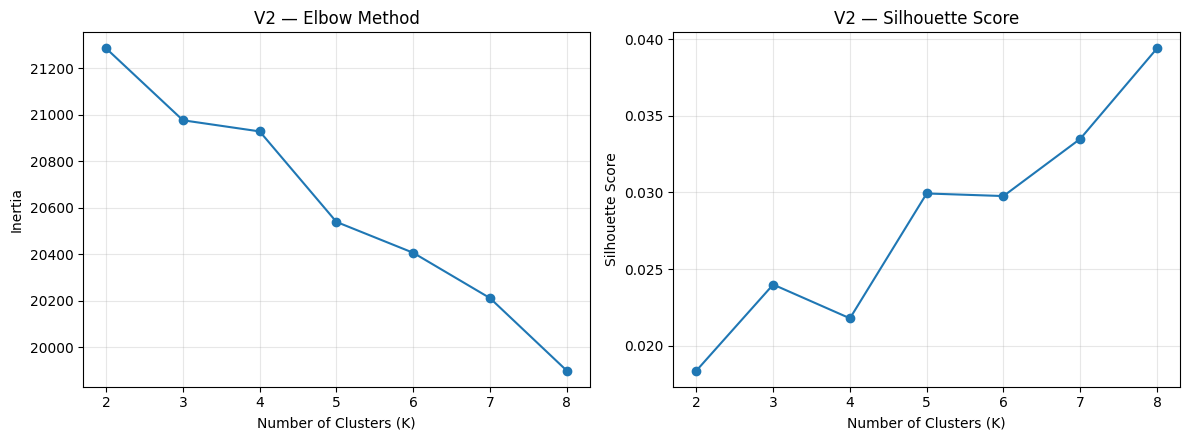

In [ ]:

# Step 54: Evaluate K for Improved Clustering (V2)

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score

results_v2 = []

for k in range(2, 9):

    model_v2 = MiniBatchKMeans(
        n_clusters=k,
        random_state=42,
        batch_size=2048,
        n_init=5,
        max_iter=100
    )

    labels_v2 = model_v2.fit_predict(X_cluster_v2)

    silhouette_v2 = silhouette_score(
        X_cluster_v2,
        labels_v2,
        sample_size=2000,
        random_state=42
    )

    results_v2.append({
        "K": k,
        "Inertia": model_v2.inertia_,
        "Silhouette": silhouette_v2
    })

    print(
        f"K={k} | "
        f"Inertia={model_v2.inertia_:.2f} | "
        f"Silhouette={silhouette_v2:.4f}"
    )

k_results_v2 = pd.DataFrame(results_v2)

print("\nImproved Clustering Evaluation:")
display(k_results_v2.round(4))

best_k_v2 = int(
    k_results_v2.loc[
        k_results_v2["Silhouette"].idxmax(),
        "K"
    ]
)

print("\nBest K for V2:", best_k_v2)

# Plot Inertia and Silhouette
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(
    k_results_v2["K"],
    k_results_v2["Inertia"],
    marker="o"
)
axes[0].set_title("V2 — Elbow Method")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")
axes[0].grid(alpha=0.3)

axes[1].plot(
    k_results_v2["K"],
    k_results_v2["Silhouette"],
    marker="o"
)
axes[1].set_title("V2 — Silhouette Score")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:

# Step 55: Train and Profile Improved K-means (V2)

import numpy as np
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import pairwise_distances

final_k_v2 = 8

# Train the selected V2 model
kmeans_v2 = MiniBatchKMeans(
    n_clusters=final_k_v2,
    random_state=42,
    batch_size=2048,
    n_init=5,
    max_iter=100
)

labels_v2 = kmeans_v2.fit_predict(X_cluster_v2)

# Save labels in the V2 dataset
df_cluster_v2["cluster_v2"] = labels_v2

# Original TF-IDF feature names
feature_names_v2 = tfidf_v2.get_feature_names_out()

print("=== CLUSTER SIZES ===")

cluster_sizes_v2 = (
    df_cluster_v2["cluster_v2"]
    .value_counts()
    .sort_index()
)

for cluster_id, count in cluster_sizes_v2.items():
    pct = 100 * count / len(df_cluster_v2)
    print(
        f"Cluster {cluster_id}: "
        f"{count:,} reviews ({pct:.2f}%)"
    )

print("\n=== TOP WORDS & REPRESENTATIVE REVIEWS ===")

for cluster_id in range(final_k_v2):

    indices = np.where(labels_v2 == cluster_id)[0]

    # Mean TF-IDF weights within each cluster
    mean_tfidf = np.asarray(
        X_tfidf_v2[indices].mean(axis=0)
    ).ravel()

    top_indices = np.argsort(mean_tfidf)[-10:][::-1]
    top_words = feature_names_v2[top_indices]

    print(f"\n========== CLUSTER {cluster_id} ==========")
    print("Top words:", ", ".join(top_words))

    # Reviews closest to the cluster centroid
    distances = pairwise_distances(
        X_cluster_v2[indices],
        kmeans_v2.cluster_centers_[cluster_id].reshape(1, -1)
    ).ravel()

    nearest_indices = indices[np.argsort(distances)[:2]]

    for i, idx in enumerate(nearest_indices, 1):
        review = df_cluster_v2.iloc[idx]["clean_text"]
        print(f"Example {i}: {review[:250]}")


=== CLUSTER SIZES ===
Cluster 0: 2,001 reviews (8.57%)
Cluster 1: 2,034 reviews (8.71%)
Cluster 2: 1,506 reviews (6.45%)
Cluster 3: 1,712 reviews (7.33%)
Cluster 4: 1,541 reviews (6.60%)
Cluster 5: 7,057 reviews (30.21%)
Cluster 6: 4,163 reviews (17.82%)
Cluster 7: 3,344 reviews (14.32%)

=== TOP WORDS & REPRESENTATIVE REVIEWS ===

========== CLUSTER 0 ==========
Top words: skin, face, smooth, sensitive, colors, feel, dry, look, soft, feels
Example 1: the cool feeling of the jade is very soothing i have rosacea that flares during a workout and the roller helped calm and cool my skin down
Example 2: i love that this is soothing and helps to heal skin only two ingredients with aloe and glycerin and organic as i continue to use this i have noticed that dark spots on the skin become lighter i will continue to purchase this brand

========== CLUSTER 1 ==========
Top words: price, quality, best, ve, better, la, muy, el, high, buy
Example 1: high quality for a low price i ll never shave with 

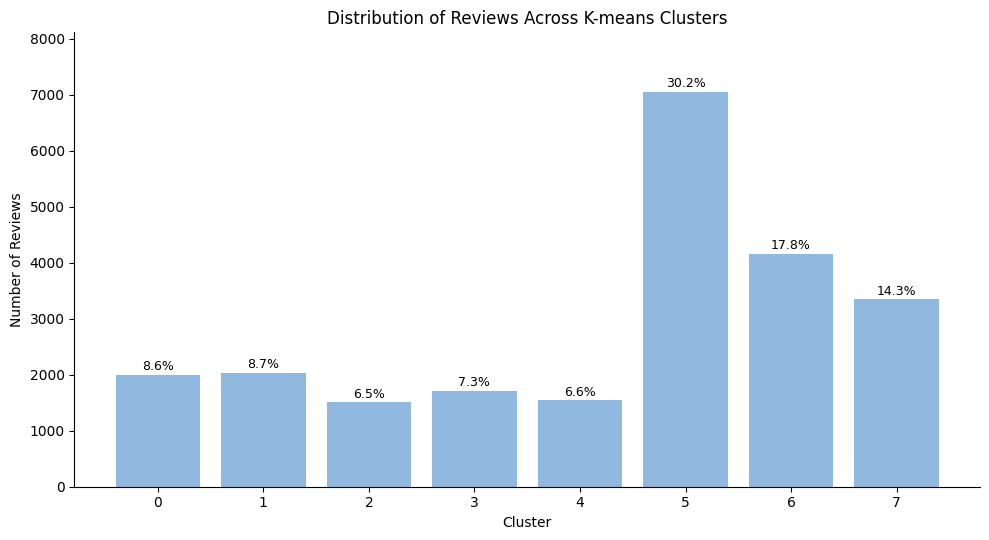

All clustering files saved successfully!
Location: /content/drive/MyDrive/Big data project/04_KMeans_Clustering


,Cluster,Tentative Label,Reviews,Percentage,Top TF-IDF Terms
0,0,Skincare & Skin Experience,2001,8.57,"skin, face, smooth, sensitive, colors"
1,1,Price & Quality,2034,8.71,"price, quality, best, ve, better"
2,2,Product Effectiveness,1506,6.45,"works, does, job, work, hair"
3,3,Nail Polish & Colors,1712,7.33,"color, nail, nails, polish, gel"
4,4,Eyelashes & Application,1541,6.60,"easy, lashes, apply, look, super"
5,5,Mixed Product Experiences,7057,30.21,"work, time, smell, don, buy"
6,6,"Size, Fit & Appearance",4163,17.82,"perfect, little, cute, size, small"
7,7,Hair Care,3344,14.32,"hair, soft, long, brush, hold"


In [ ]:

# Step 56: Save K-means Results and Figure

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

output_dir = Path(
    "/content/drive/MyDrive/Big data project/"
    "04_KMeans_Clustering"
)
output_dir.mkdir(parents=True, exist_ok=True)

# Tentative interpretations based on observed terms
cluster_names = {
    0: "Skincare & Skin Experience",
    1: "Price & Quality",
    2: "Product Effectiveness",
    3: "Nail Polish & Colors",
    4: "Eyelashes & Application",
    5: "Mixed Product Experiences",
    6: "Size, Fit & Appearance",
    7: "Hair Care"
}

# Create Table 4
records = []

feature_names = tfidf_v2.get_feature_names_out()

for cluster_id in range(8):

    indices = np.where(
        labels_v2 == cluster_id
    )[0]

    mean_tfidf = np.asarray(
        X_tfidf_v2[indices].mean(axis=0)
    ).ravel()

    top_indices = np.argsort(
        mean_tfidf
    )[-5:][::-1]

    top_words = ", ".join(
        feature_names[top_indices]
    )

    records.append({
        "Cluster": cluster_id,
        "Tentative Label": cluster_names[cluster_id],
        "Reviews": len(indices),
        "Percentage": round(
            len(indices) / len(df_cluster_v2) * 100, 2
        ),
        "Top TF-IDF Terms": top_words
    })

table4 = pd.DataFrame(records)

table4.to_csv(
    output_dir / "Table4_KMeans_Cluster_Profiles.csv",
    index=False
)

# Save evaluation results
k_results_v2.to_csv(
    output_dir / "KMeans_V2_Evaluation.csv",
    index=False
)

k_results.to_csv(
    output_dir / "KMeans_V1_Evaluation.csv",
    index=False
)

# Create Figure: cluster distribution
fig, ax = plt.subplots(figsize=(10, 5.5))

bars = ax.bar(
    table4["Cluster"].astype(str),
    table4["Reviews"],
    color="#91B8DE"
)

for bar, pct in zip(bars, table4["Percentage"]):
    ax.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 85,
        f"{pct:.1f}%",
        ha="center",
        fontsize=9
    )

ax.set_ylim(0, table4["Reviews"].max() * 1.15)
ax.set_xlabel("Cluster")
ax.set_ylabel("Number of Reviews")
ax.set_title(
    "Distribution of Reviews Across K-means Clusters"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    output_dir / "Figure4_KMeans_Clusters.png",
    dpi=300,
    bbox_inches="tight"
)
plt.savefig(
    output_dir / "Figure4_KMeans_Clusters.pdf",
    bbox_inches="tight"
)

plt.show()

print("All clustering files saved successfully!")
print("Location:", output_dir)

display(table4)


In [ ]:

# Step 57: Prepare Classification Dataset

import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

# 1. Keep positive and negative ratings only
df_cls = df_clean[
    df_clean["rating"].isin([1, 2, 4, 5])
].copy()

# 2. Remove missing / empty review texts
df_cls = df_cls.dropna(subset=["text"])

df_cls["text"] = df_cls["text"].astype(str)

df_cls = df_cls[
    df_cls["text"].str.strip().ne("")
].copy()

# 3. Create binary labels
# 0 = Negative, 1 = Positive
df_cls["label"] = (
    df_cls["rating"] >= 4
).astype(int)

# 4. Normalize text only for duplicate-group detection
df_cls["text_group"] = (
    df_cls["text"]
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# 5. Split by text groups to avoid exact-text leakage
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(
        df_cls,
        y=df_cls["label"],
        groups=df_cls["text_group"]
    )
)

train_df = df_cls.iloc[train_idx].copy()
test_df = df_cls.iloc[test_idx].copy()

# 6. Check for group leakage
overlap = set(train_df["text_group"]) & set(
    test_df["text_group"]
)

print("=== CLASSIFICATION DATASET ===")
print("Total labeled reviews:", len(df_cls))
print("Training reviews:", len(train_df))
print("Testing reviews:", len(test_df))

print("\n=== CLASS DISTRIBUTION ===")
print(df_cls["label"].value_counts())

print("\n=== TRAINING DISTRIBUTION (%) ===")
print(
    (train_df["label"].value_counts(normalize=True)
     * 100).round(2)
)

print("\n=== TESTING DISTRIBUTION (%) ===")
print(
    (test_df["label"].value_counts(normalize=True)
     * 100).round(2)
)

print("\nOverlapping text groups:", len(overlap))
print(
    "Majority-class baseline accuracy:",
    round(
        test_df["label"].value_counts(normalize=True).max(),
        4
    )
)


=== CLASSIFICATION DATASET ===
Total labeled reviews: 637851
Training reviews: 509359
Testing reviews: 128492

=== CLASS DISTRIBUTION ===
label
1    494518
0    143333
Name: count, dtype: int64

=== TRAINING DISTRIBUTION (%) ===
label
1    77.47
0    22.53
Name: proportion, dtype: float64

=== TESTING DISTRIBUTION (%) ===
label
1    77.74
0    22.26
Name: proportion, dtype: float64

Overlapping text groups: 0
Majority-class baseline accuracy: 0.7774


In [ ]:

# Step 58: Train Naive Bayes and Linear SVM

import numpy as np
import pandas as pd

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

# 1. Prepare text and labels
X_train_text = train_df["text"].astype(str)
X_test_text = test_df["text"].astype(str)

y_train = train_df["label"].to_numpy()
y_test = test_df["label"].to_numpy()

# 2. Convert text to TF-IDF
# Fit on training data ONLY to avoid leakage
tfidf_cls = TfidfVectorizer(
    max_features=25000,
    min_df=5,
    max_df=0.95,
    sublinear_tf=True,
    strip_accents="unicode",
    dtype=np.float32
)

X_train = tfidf_cls.fit_transform(X_train_text)
X_test = tfidf_cls.transform(X_test_text)

print("Training matrix:", X_train.shape)
print("Testing matrix:", X_test.shape)

# 3. Define models
models = {
    "Naive Bayes": MultinomialNB(alpha=1.0),

    "Linear SVM": LinearSVC(
        class_weight="balanced",
        random_state=42,
        max_iter=2000
    )
}

# 4. Train and evaluate
classification_results = []
predictions = {}

for name, model in models.items():

    print(f"\nTraining {name}...")

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        )
    )

    negative_recall = (
        recall_score_value
        if False else
        precision_recall_fscore_support(
            y_test,
            y_pred,
            labels=[0],
            average=None,
            zero_division=0
        )[1][0]
    )

    classification_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": f1,
        "Negative Recall": negative_recall
    })

    print(f"\n{name} — Classification Report")
    print(
        classification_report(
            y_test,
            y_pred,
            labels=[0, 1],
            target_names=["Negative", "Positive"],
            digits=4,
            zero_division=0
        )
    )

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred, labels=[0, 1]))

# 5. Compare models
results_cls = pd.DataFrame(classification_results)

print("\n=== MODEL COMPARISON ===")
display(results_cls.round(4))


Training matrix: (509359, 22742)
Testing matrix: (128492, 22742)

Training Naive Bayes...

Naive Bayes — Classification Report
              precision    recall  f1-score   support

    Negative     0.9294    0.5242    0.6703     28596
    Positive     0.8789    0.9886    0.9305     99896

    accuracy                         0.8852    128492
   macro avg     0.9041    0.7564    0.8004    128492
weighted avg     0.8901    0.8852    0.8726    128492

Confusion Matrix:
[[14989 13607]
 [ 1139 98757]]

Training Linear SVM...

Linear SVM — Classification Report
              precision    recall  f1-score   support

    Negative     0.7574    0.9186    0.8303     28596
    Positive     0.9752    0.9158    0.9445     99896

    accuracy                         0.9164    128492
   macro avg     0.8663    0.9172    0.8874    128492
weighted avg     0.9267    0.9164    0.9191    128492

Confusion Matrix:
[[26269  2327]
 [ 8414 91482]]

=== MODEL COMPARISON ===


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Negative Recall
0,Naive Bayes,0.8852,0.9041,0.7564,0.8004,0.5242
1,Linear SVM,0.9164,0.8663,0.9172,0.8874,0.9186


Table 5:


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Negative Recall
0,Naive Bayes,88.52,90.41,75.64,80.04,52.42
1,Linear SVM,91.64,86.63,91.72,88.74,91.86


/usr/local/lib/python3.13/dist-packages/matplotlib/backends/backend_pdf.py:1761: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(rgb8, mode='P')


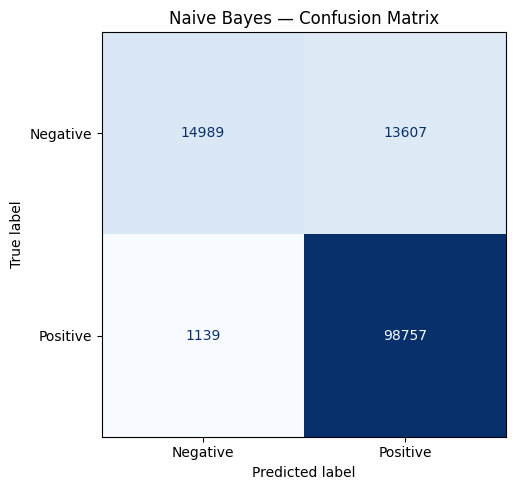

/usr/local/lib/python3.13/dist-packages/matplotlib/backends/backend_pdf.py:1761: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(rgb8, mode='P')


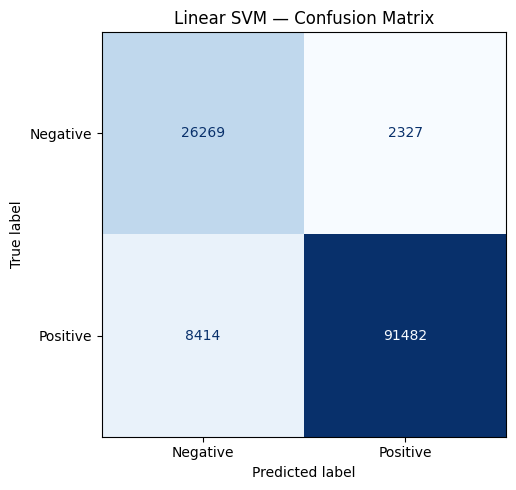


All classification files saved successfully!
Location: /content/drive/MyDrive/Big data project/05_Classification


In [ ]:

# Step 59: Save Classification Results

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    confusion_matrix,
    classification_report
)
import joblib

output_dir = Path(
    "/content/drive/MyDrive/Big data project/"
    "05_Classification"
)

output_dir.mkdir(parents=True, exist_ok=True)

# 1. Table 5 - Model Comparison
table5 = results_cls.copy()

metric_columns = [
    "Accuracy", "Macro Precision",
    "Macro Recall", "Macro F1",
    "Negative Recall"
]

table5[metric_columns] = (
    table5[metric_columns] * 100
).round(2)

table5.to_csv(
    output_dir / "Table5_Classification_Comparison.csv",
    index=False
)

print("Table 5:")
display(table5)

# 2. Save confusion matrices and figures
for name, y_pred in predictions.items():

    filename = name.replace(" ", "_")

    cm = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    )

    cm_df = pd.DataFrame(
        cm,
        index=["Actual Negative", "Actual Positive"],
        columns=["Predicted Negative", "Predicted Positive"]
    )

    cm_df.to_csv(
        output_dir / f"{filename}_Confusion_Matrix.csv"
    )

    fig, ax = plt.subplots(figsize=(6, 5))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Negative", "Positive"]
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    ax.set_title(f"{name} — Confusion Matrix")
    plt.tight_layout()

    plt.savefig(
        output_dir / f"{filename}_Confusion_Matrix.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.savefig(
        output_dir / f"{filename}_Confusion_Matrix.pdf",
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    report = classification_report(
        y_test,
        y_pred,
        target_names=["Negative", "Positive"],
        digits=4,
        zero_division=0
    )

    (output_dir / f"{filename}_Report.txt").write_text(
        report
    )

# 3. Save trained TF-IDF and models
joblib.dump(
    tfidf_cls,
    output_dir / "TFIDF_Vectorizer.joblib"
)

for name, model in models.items():
    filename = name.replace(" ", "_")
    joblib.dump(
        model,
        output_dir / f"{filename}_Model.joblib"
    )

print("\nAll classification files saved successfully!")
print("Location:", output_dir)


/usr/local/lib/python3.13/dist-packages/matplotlib/backends/backend_pdf.py:1761: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(rgb8, mode='P')
/usr/local/lib/python3.13/dist-packages/matplotlib/backends/backend_pdf.py:1761: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(rgb8, mode='P')


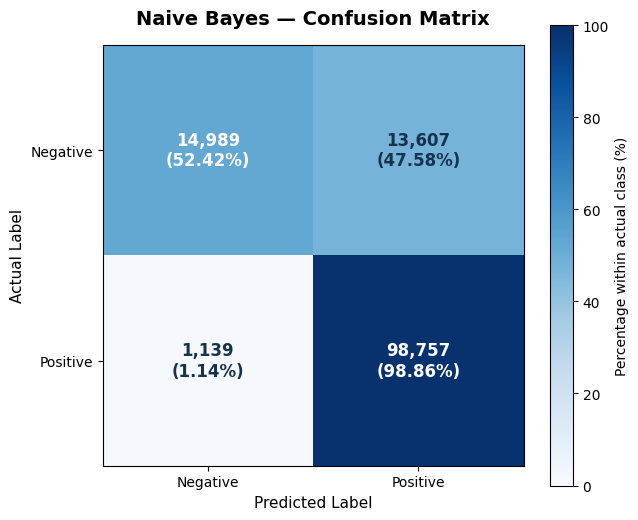

/usr/local/lib/python3.13/dist-packages/matplotlib/backends/backend_pdf.py:1761: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(rgb8, mode='P')
/usr/local/lib/python3.13/dist-packages/matplotlib/backends/backend_pdf.py:1761: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(rgb8, mode='P')


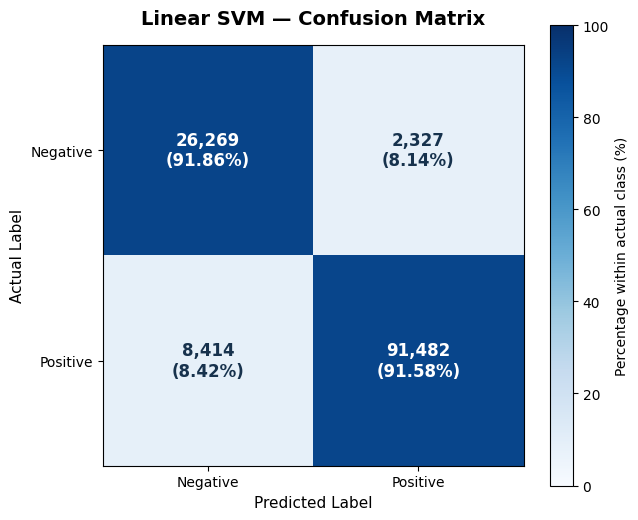

Improved confusion matrices saved successfully!


In [ ]:

# Step 59B: Publication-ready Confusion Matrices
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

for name, y_pred in predictions.items():

    cm = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    )

    # Normalize each actual-class row
    cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100

    fig, ax = plt.subplots(figsize=(6.5, 5.5))

    im = ax.imshow(
        cm_pct,
        cmap="Blues",
        vmin=0,
        vmax=100
    )

    for i in range(2):
        for j in range(2):
            value = cm_pct[i, j]
            ax.text(
                j, i,
                f"{cm[i,j]:,}\n({value:.2f}%)",
                ha="center",
                va="center",
                fontsize=12,
                fontweight="bold",
                color="white" if value > 50 else "#17324D"
            )

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])

    ax.set_xticklabels(["Negative", "Positive"])
    ax.set_yticklabels(["Negative", "Positive"])

    ax.set_xlabel("Predicted Label", fontsize=11)
    ax.set_ylabel("Actual Label", fontsize=11)
    ax.set_title(
        f"{name} — Confusion Matrix",
        fontsize=14,
        fontweight="bold",
        pad=15
    )

    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label("Percentage within actual class (%)")

    plt.tight_layout()

    filename = name.replace(" ", "_")

    plt.savefig(
        output_dir / f"{filename}_Confusion_Matrix_Improved.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.savefig(
        output_dir / f"{filename}_Confusion_Matrix_Improved.pdf",
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

print("Improved confusion matrices saved successfully!")


In [ ]:

# Step 60: Lexicon-Based Sentiment Analysis using VADER

!pip -q install vaderSentiment

import numpy as np
import pandas as pd
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

# 1. Prepare test data with existing SVM predictions
sentiment_data = test_df.reset_index(drop=True).copy()

sentiment_data["svm_prediction"] = (
    predictions["Linear SVM"]
)

# 2. Reproducible test sample
sentiment_sample = sentiment_data.sample(
    n=20000,
    random_state=42
).copy()

print("Sentiment sample:", len(sentiment_sample))

# 3. Initialize VADER
analyzer = SentimentIntensityAnalyzer()

# 4. Calculate sentiment compound scores
sentiment_sample["vader_score"] = (
    sentiment_sample["text"]
    .astype(str)
    .apply(
        lambda text:
        analyzer.polarity_scores(text)["compound"]
    )
)

# 5. Standard VADER sentiment categories
def vader_label(score):
    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    else:
        return "Neutral"

sentiment_sample["vader_sentiment"] = (
    sentiment_sample["vader_score"].apply(vader_label)
)

print("\n=== VADER SENTIMENT DISTRIBUTION ===")
print(
    sentiment_sample["vader_sentiment"]
    .value_counts()
)

print("\n=== AVERAGE SENTIMENT SCORE ===")
print(
    round(
        sentiment_sample["vader_score"].mean(),
        4
    )
)

print("\n=== SAMPLE RESULTS ===")

display(
    sentiment_sample[
        ["rating", "text",
         "vader_score", "vader_sentiment"]
    ].head(5)
)


Sentiment sample: 20000

=== VADER SENTIMENT DISTRIBUTION ===
vader_sentiment
Positive    15225
Negative     2709
Neutral      2066
Name: count, dtype: int64

=== AVERAGE SENTIMENT SCORE ===
0.473

=== SAMPLE RESULTS ===


,rating,text,vader_score,vader_sentiment
64128,5,worth every penny,0.2263,Positive
115002,5,My hair has always had that curl to it. This ...,0.8146,Positive
36103,5,it was great,0.6249,Positive
5326,5,I didn't purchase this from Amazon but I did f...,0.9755,Positive
43762,5,These lashes were easy to install and so much ...,0.8214,Positive


In [ ]:

# Step 61: Fair Comparison — VADER vs Linear SVM

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix
)

# 1. Convert non-neutral VADER predictions to binary
vader_map = {
    "Negative": 0,
    "Positive": 1
}

sentiment_sample["vader_binary"] = (
    sentiment_sample["vader_sentiment"].map(vader_map)
)

# 2. Keep only reviews VADER classified as non-neutral
comparison = sentiment_sample[
    sentiment_sample["vader_binary"].notna()
].copy()

coverage = len(comparison) / len(sentiment_sample)

print("=== COMPARISON SAMPLE ===")
print("Total reviews:", len(sentiment_sample))
print("Non-neutral reviews:", len(comparison))
print("Neutral / abstained:",
      len(sentiment_sample) - len(comparison))
print("VADER coverage:", f"{coverage:.2%}")

# 3. Evaluate both on exactly the same reviews
y_true = comparison["label"].astype(int)

comparison_results = []

for name, prediction_column in [
    ("VADER", "vader_binary"),
    ("Linear SVM", "svm_prediction")
]:
    y_pred = comparison[prediction_column].astype(int)

    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            y_true, y_pred,
            average="macro",
            zero_division=0
        )
    )

    negative_recall = (
        precision_recall_fscore_support(
            y_true, y_pred,
            labels=[0],
            average=None,
            zero_division=0
        )[1][0]
    )

    comparison_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro F1": f1,
        "Negative Recall": negative_recall
    })

    print(f"\n{name} Confusion Matrix:")
    print(confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ))

comparison_table = pd.DataFrame(comparison_results)

print("\n=== VADER VS SVM ===")
display(comparison_table.round(4))

# 4. Inspect actual rating groups among VADER-neutral reviews
neutral_reviews = sentiment_sample[
    sentiment_sample["vader_sentiment"] == "Neutral"
]

print("\n=== VADER NEUTRAL — ACTUAL RATINGS ===")
print(neutral_reviews["label"].value_counts())


=== COMPARISON SAMPLE ===
Total reviews: 20000
Non-neutral reviews: 17934
Neutral / abstained: 2066
VADER coverage: 89.67%

VADER Confusion Matrix:
[[ 2157  1479]
 [  552 13746]]

Linear SVM Confusion Matrix:
[[ 3331   305]
 [ 1004 13294]]

=== VADER VS SVM ===


,Model,Accuracy,Macro F1,Negative Recall
0,VADER,0.8868,0.8056,0.5932
1,Linear SVM,0.9270,0.8944,0.9161



=== VADER NEUTRAL — ACTUAL RATINGS ===
label
1    1178
0     888
Name: count, dtype: int64


In [ ]:

# Step 61B: Compare VADER vs SVM on ALL 20,000 reviews

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    confusion_matrix
)

# Binary conversion for VADER
# Negative if score < 0, otherwise Positive
sentiment_sample["vader_binary_all"] = (
    sentiment_sample["vader_score"] >= 0
).astype(int)

results_all = []

for name, column in [
    ("VADER", "vader_binary_all"),
    ("Linear SVM", "svm_prediction")
]:
    y_true = sentiment_sample["label"].astype(int)
    y_pred = sentiment_sample[column].astype(int)

    results_all.append({
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro F1": f1_score(
            y_true, y_pred, average="macro"
        ),
        "Negative Recall": recall_score(
            y_true, y_pred, pos_label=0
        )
    })

    print(f"\n{name} Confusion Matrix:")
    print(confusion_matrix(y_true, y_pred, labels=[0, 1]))

results_all_df = pd.DataFrame(results_all)

print("\n=== FULL 20,000 REVIEW COMPARISON ===")
display(results_all_df.round(4))



VADER Confusion Matrix:
[[ 2196  2328]
 [  592 14884]]

Linear SVM Confusion Matrix:
[[ 4167   357]
 [ 1304 14172]]

=== FULL 20,000 REVIEW COMPARISON ===


,Model,Accuracy,Macro F1,Negative Recall
0,VADER,0.854,0.7557,0.4854
1,Linear SVM,0.917,0.8892,0.9211


In [ ]:

# Step 61C: Full Test Set — VADER vs Linear SVM

import pandas as pd
from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    confusion_matrix
)

# Use exactly the same test rows and order
full_sentiment = test_df.reset_index(drop=True).copy()

full_sentiment["svm_prediction"] = (
    predictions["Linear SVM"]
)

# Apply VADER to all test reviews
full_sentiment["vader_score"] = (
    full_sentiment["text"].astype(str).map(
        lambda text:
        analyzer.polarity_scores(text)["compound"]
    )
)

# Binary threshold for comparison
full_sentiment["vader_prediction"] = (
    full_sentiment["vader_score"] >= 0
).astype(int)

y_true = full_sentiment["label"].astype(int)

results_full = []

for name, col in [
    ("VADER", "vader_prediction"),
    ("Linear SVM", "svm_prediction")
]:
    y_pred = full_sentiment[col].astype(int)

    results_full.append({
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro F1": f1_score(
            y_true, y_pred, average="macro"
        ),
        "Negative Recall": recall_score(
            y_true, y_pred, pos_label=0
        )
    })

    print(f"\n{name} Confusion Matrix:")
    print(confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ))

table_sentiment = pd.DataFrame(results_full)

print("\n=== FULL TEST SET COMPARISON ===")
print("Reviews evaluated:", len(full_sentiment))
display(table_sentiment.round(4))

# Save results to Google Drive
output_dir = Path(
    "/content/drive/MyDrive/Big data project/"
    "07_Text_Sentiment"
)
output_dir.mkdir(parents=True, exist_ok=True)

table_sentiment.to_csv(
    output_dir / "VADER_vs_SVM_Full_Test.csv",
    index=False
)

print("\nComparison table saved successfully!")



VADER Confusion Matrix:
[[13866 14730]
 [ 3661 96235]]

Linear SVM Confusion Matrix:
[[26269  2327]
 [ 8414 91482]]

=== FULL TEST SET COMPARISON ===
Reviews evaluated: 128492


,Model,Accuracy,Macro F1,Negative Recall
0,VADER,0.8569,0.7570,0.4849
1,Linear SVM,0.9164,0.8874,0.9186



Comparison table saved successfully!


In [ ]:

# Step 62: Topic Modeling on ALL negative test reviews

import re
import html
import numpy as np
from sklearn.feature_extraction.text import (
    TfidfVectorizer, ENGLISH_STOP_WORDS
)
from sklearn.decomposition import NMF

# 1. All low-rating reviews in the test set
negative_reviews = full_sentiment[
    full_sentiment["label"] == 0
].copy().reset_index(drop=True)

print("Negative reviews:", len(negative_reviews))

# 2. Clean HTML artifacts
def clean_topic_text(text):
    text = html.unescape(str(text))
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"\[\[ASIN:[^\]]+\]\]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip().lower()

negative_reviews["topic_text"] = (
    negative_reviews["text"].map(clean_topic_text)
)

# 3. Filter generic review words
extra_stopwords = {
    "product", "products", "amazon",
    "buy", "bought", "purchase",
    "good", "great", "love", "like",
    "just", "really", "br",
    "did", "didn", "don", "doesn",
    "ve", "ll", "wasn"
}

topic_stopwords = list(
    ENGLISH_STOP_WORDS.union(extra_stopwords)
)

# 4. TF-IDF
tfidf_topics = TfidfVectorizer(
    stop_words=topic_stopwords,
    max_features=4000,
    min_df=10,
    max_df=0.90,
    ngram_range=(1, 2),
    strip_accents="unicode"
)

X_topics = tfidf_topics.fit_transform(
    negative_reviews["topic_text"]
)

print("TF-IDF shape:", X_topics.shape)

# 5. Extract 5 exploratory topics
n_topics = 5

nmf_model = NMF(
    n_components=n_topics,
    init="nndsvda",
    random_state=42,
    max_iter=400
)

W = nmf_model.fit_transform(X_topics)
H = nmf_model.components_

words = tfidf_topics.get_feature_names_out()

print("\n=== DISCOVERED TOPICS ===")

for topic_id, weights in enumerate(H):
    top_indices = weights.argsort()[-12:][::-1]
    top_terms = words[top_indices]

    print(
        f"Topic {topic_id + 1}: "
        + ", ".join(top_terms)
    )

# 6. Dominant topic per review
negative_reviews["topic"] = W.argmax(axis=1) + 1

print("\n=== TOPIC DISTRIBUTION ===")
print(
    negative_reviews["topic"]
    .value_counts()
    .sort_index()
)

# 7. Representative examples
print("\n=== REPRESENTATIVE REVIEWS ===")

for topic_id in range(n_topics):
    idx = np.argmax(W[:, topic_id])

    print(f"\nTopic {topic_id + 1}:")
    print(
        negative_reviews.iloc[idx]["text"][:350]
    )


Negative reviews: 28596
TF-IDF shape: (28596, 4000)

=== DISCOVERED TOPICS ===
Topic 1: work, does work, does, work hair, work waste, tried, work advertised, money work, doesnt work, work tried, work better, hard work
Topic 2: hair, human, human hair, hold, sheds, brush, synthetic, tangled, curl, hair hair, tangles, hold hair
Topic 3: money, waste, waste money, worth, work waste, worth money, time, save, save money, waste time, total, total waste
Topic 4: use, used, disappointed, color, small, smell, time, does, skin, came, way, broke
Topic 5: quality, poor, poor quality, cheap, bad, bad quality, terrible, worth, cheap quality, terrible quality, quality hair, low

=== TOPIC DISTRIBUTION ===
topic
1     1748
2     3811
3     1983
4    19426
5     1628
Name: count, dtype: int64

=== REPRESENTATIVE REVIEWS ===

Topic 1:
Did not work

Topic 2:
Not for thick hair

Topic 3:
don't waste your money...

Topic 4:
Confusing to use

Topic 5:
Cheap, hence poor quality


In [ ]:

# Step 63: Improve Topic Modeling
# Preserve negation and explore 8 topics

import re
import html
import numpy as np
import pandas as pd

from sklearn.feature_extraction.text import (
    TfidfVectorizer, ENGLISH_STOP_WORDS
)
from sklearn.decomposition import NMF

# 1. Clean text while preserving negation
def clean_topic_text_v2(text):
    text = html.unescape(str(text)).lower()

    text = re.sub(
        r"\[\[asin:[^\]]+\]\]", " ", text
    )
    text = re.sub(r"<[^>]+>", " ", text)

    # Expand common negative contractions
    text = re.sub(r"\bwon['’]t\b", "will not", text)
    text = re.sub(r"\bcan['’]t\b", "can not", text)
    text = re.sub(
        r"\b([a-z]+)n['’]t\b",
        r"\1 not",
        text
    )

    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()

    return text

negative_reviews["topic_text_v2"] = (
    negative_reviews["text"].map(clean_topic_text_v2)
)

# 2. Remove generic words but preserve negation
negation_words = {"no", "not", "nor", "never"}

generic_words = {
    "product", "products", "amazon",
    "buy", "bought", "purchase",
    "good", "great", "love", "like",
    "just", "really", "br",
    "use", "used", "using",
    "ve", "ll"
}

topic_stopwords_v2 = list(
    (set(ENGLISH_STOP_WORDS) - negation_words)
    | generic_words
)

# 3. TF-IDF with unigrams and bigrams
tfidf_topics_v2 = TfidfVectorizer(
    stop_words=topic_stopwords_v2,
    max_features=5000,
    min_df=10,
    max_df=0.90,
    ngram_range=(1, 2),
    strip_accents="unicode"
)

X_topics_v2 = tfidf_topics_v2.fit_transform(
    negative_reviews["topic_text_v2"]
)

# 4. Discover 8 exploratory topics
n_topics_v2 = 8

nmf_v2 = NMF(
    n_components=n_topics_v2,
    init="nndsvda",
    random_state=42,
    max_iter=400
)

W_v2 = nmf_v2.fit_transform(X_topics_v2)
H_v2 = nmf_v2.components_

words_v2 = tfidf_topics_v2.get_feature_names_out()

print("TF-IDF shape:", X_topics_v2.shape)
print("Negation preserved:", "not" in words_v2)

print("\n=== IMPROVED TOPICS ===")

for topic_id, weights in enumerate(H_v2):
    top_indices = np.argsort(weights)[-12:][::-1]
    print(
        f"Topic {topic_id + 1}: "
        + ", ".join(words_v2[top_indices])
    )

# 5. Assign dominant topic
negative_reviews["topic_v2"] = (
    W_v2.argmax(axis=1) + 1
)

topic_distribution_v2 = (
    negative_reviews["topic_v2"]
    .value_counts()
    .sort_index()
)

print("\n=== IMPROVED TOPIC DISTRIBUTION ===")

for topic_id, count in topic_distribution_v2.items():
    percentage = count / len(negative_reviews) * 100
    print(
        f"Topic {topic_id}: "
        f"{count:,} reviews ({percentage:.2f}%)"
    )

# 6. Representative reviews with at least 12 words
print("\n=== REPRESENTATIVE REVIEWS ===")

word_counts = (
    negative_reviews["topic_text_v2"]
    .str.split()
    .str.len()
    .to_numpy()
)

for topic_id in range(n_topics_v2):

    candidates = np.where(word_counts >= 12)[0]

    best_idx = candidates[
        np.argmax(W_v2[candidates, topic_id])
    ]

    print(f"\nTopic {topic_id + 1}:")
    print(
        negative_reviews.iloc[best_idx]["text"][:300]
    )


TF-IDF shape: (28596, 5000)
Negation preserved: True

=== IMPROVED TOPICS ===
Topic 1: not, not recommend, recommend, stay, not not, not stay, expected, not expected, not happy, stick, happy, easy
Topic 2: did, did not, not work, work, not, work not, not did, work did, tried, not fit, not come, hair did
Topic 3: does, does not, not work, work, not, not stay, stay, work not, not hold, smell, hold, not smell
Topic 4: waste, money, waste money, not waste, money not, time, waste time, total, save, total waste, save money, complete waste
Topic 5: hair, hair not, not hair, human, human hair, hold, sheds, brush, tangled, synthetic, tangles, curl
Topic 6: no, disappointed, small, color, way, came, time, got, received, broke, broken, skin
Topic 7: worth, not worth, worth money, not, money, price, worth price, definitely, definitely not, worth time, worth buying, paid
Topic 8: quality, poor, cheap, poor quality, quality not, broke, not quality, bad quality, bad, terrible, cheap quality, terrible

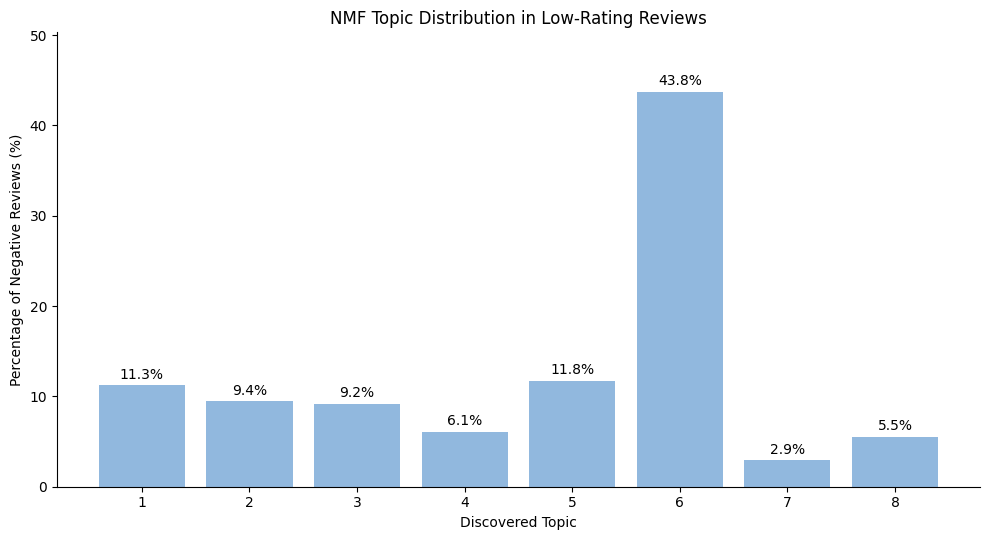

Topic Modeling files saved successfully!
Location: /content/drive/MyDrive/Big data project/07_Text_Sentiment


,Topic,Tentative Label,Reviews,Percentage,Top Terms
0,1,Recommendation & Expectations,3221,11.26,"not, not recommend, recommend, stay, not not, ..."
1,2,Product Failure - Did Not Work,2703,9.45,"did, did not, not work, work, not, work not, n..."
2,3,Product Ineffectiveness,2633,9.21,"does, does not, not work, work, not, not stay,..."
3,4,Waste of Money,1744,6.10,"waste, money, waste money, not waste, money no..."
4,5,Hair-related Issues,3362,11.76,"hair, hair not, not hair, human, human hair, h..."
5,6,Mixed Product Complaints,12511,43.75,"no, disappointed, small, color, way, came, tim..."
6,7,Poor Value for Money,841,2.94,"worth, not worth, worth money, not, money, pri..."
7,8,Poor Product Quality,1581,5.53,"quality, poor, cheap, poor quality, quality no..."


In [ ]:

# Step 64: Save NMF Topic Modeling Results

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import joblib

output_dir = Path(
    "/content/drive/MyDrive/Big data project/"
    "07_Text_Sentiment"
)
output_dir.mkdir(parents=True, exist_ok=True)

topic_labels = {
    1: "Recommendation & Expectations",
    2: "Product Failure - Did Not Work",
    3: "Product Ineffectiveness",
    4: "Waste of Money",
    5: "Hair-related Issues",
    6: "Mixed Product Complaints",
    7: "Poor Value for Money",
    8: "Poor Product Quality"
}

# Create topic summary
topic_records = []

for topic_id in range(1, 9):
    indices = np.argsort(
        H_v2[topic_id - 1]
    )[-10:][::-1]

    top_terms = ", ".join(words_v2[indices])

    count = int(
        (negative_reviews["topic_v2"] == topic_id).sum()
    )

    topic_records.append({
        "Topic": topic_id,
        "Tentative Label": topic_labels[topic_id],
        "Reviews": count,
        "Percentage": round(
            100 * count / len(negative_reviews), 2
        ),
        "Top Terms": top_terms
    })

topic_table = pd.DataFrame(topic_records)

topic_table.to_csv(
    output_dir / "NMF_Topic_Profiles.csv",
    index=False
)

# Save review-level assignments
negative_reviews[
    ["rating", "topic_v2", "topic_text_v2"]
].to_csv(
    output_dir / "Negative_Review_Topic_Assignments.csv",
    index=False
)

# Save reproducible models
joblib.dump(
    tfidf_topics_v2,
    output_dir / "NMF_TFIDF_Vectorizer.joblib"
)

joblib.dump(
    nmf_v2,
    output_dir / "NMF_8Topics_Model.joblib"
)

# Plot topic distribution
fig, ax = plt.subplots(figsize=(10, 5.5))

bars = ax.bar(
    topic_table["Topic"].astype(str),
    topic_table["Percentage"],
    color="#91B8DE"
)

for bar, value in zip(
    bars, topic_table["Percentage"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.7,
        f"{value:.1f}%",
        ha="center",
        fontsize=10
    )

ax.set_ylim(
    0,
    topic_table["Percentage"].max() * 1.15
)

ax.set_xlabel("Discovered Topic")
ax.set_ylabel("Percentage of Negative Reviews (%)")
ax.set_title(
    "NMF Topic Distribution in Low-Rating Reviews"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    output_dir / "NMF_Topic_Distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    output_dir / "NMF_Topic_Distribution.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Topic Modeling files saved successfully!")
print("Location:", output_dir)

display(topic_table)
